# 🎯 Notebook 08 — RQ5: Novel Cross-Modal Attention Architecture

---

> **RQ5:** Is it feasible that the proposed cross-modal attention-based model outperforms other methods of fusion to obtain clinical-level precision (MAE < 15ms)?

## Novel Contribution
This is the core of the research: a **Bidirectional Cross-Modal Attention** model where ICG and ECG modalities dynamically attend to each other to correct ICG timing bias.

**Clinical motivation:** The ICG B-point (estimated valve opening) is electrically triggered — the aortic valve opens because of the action potential captured by the ECG. By letting ICG features *attend* to ECG features at the exact temporal scale of cardiac events, the model learns the electromechanical delay that causes the bias.

## Architecture Overview
```
ICG (B,1,256)          ECG (B,1,256)
     │                      │
 ResNet1D              ResNet1D
  Encoder               Encoder
     │                      │
 F_icg (B,256,16)    F_ecg (B,256,16)
     │                      │
     └──── Learnable PE ─────┘
     │                      │
     ▼          ▼           ▼          ▼
  Q=F_icg    K,V=F_ecg   Q=F_ecg   K,V=F_icg
     │          │           │          │
  MHA (ICG→ECG)          MHA (ECG→ICG)
  + FFN + ResNorm         + FFN + ResNorm
     │                      │
  A_icg (B,16,256)       A_ecg (B,16,256)
     │                      │
     └──── Concat ─────────┘
           │
     (B,16,512)
           │
     Global Avg Pool
           │
     MLP Head
           │
     [PEP, LVET] (ms)
```

## What Makes This Novel
| Feature | This Work | Previous Methods |
|---|---|---|
| Attention mechanism | Bidirectional cross-modal | None / self-attention only |
| Encoder | 1D ResNet with residual blocks | Simple CNN |
| Electromechanical modelling | Explicit (Q attends to K/V from partner modality) | Implicit or none |
| Attention direction | ICG→ECG AND ECG→ICG | Single direction |
| Target domain | Cardiac timing bias correction | General regression |

---
**Install if needed:** `pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118`

In [1]:
# ============================================================
#  CONFIGURATION — adjust paths if needed
# ============================================================
FINAL_DATASET_DIR  = './output/final_dataset'
RESULTS_DIR_RQ2    = './output/results/rq2_ml_baselines'
RESULTS_DIR_RQ3    = './output/results/rq3_single_modality'
RESULTS_DIR_RQ4    = './output/results/rq4_multimodal_fusion'
RESULTS_DIR        = './output/results/rq5_cross_modal_attention'

import os
for d in [RESULTS_DIR, f'{RESULTS_DIR}/figures', f'{RESULTS_DIR}/checkpoints', f'{RESULTS_DIR}/attention_weights']:
    os.makedirs(d, exist_ok=True)
print('Directories ready.')

Directories ready.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import json, warnings, time, math
from pathlib import Path
from copy import deepcopy
from scipy import stats as scipy_stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from torch.cuda.amp import GradScaler, autocast

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 11,
    'font.family': 'DejaVu Sans'
})

# ── GPU Setup ──────────────────────────────────────────────────
if torch.cuda.is_available():
    device = torch.device('cuda')
    torch.backends.cudnn.benchmark     = True   # speed up conv with fixed input size
    torch.backends.cudnn.deterministic = False  # allow non-deterministic for speed
    print(f'🖥️  GPU: {torch.cuda.get_device_name(0)}')
    total_vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'   VRAM: {total_vram:.1f} GB')
    USE_AMP = True   # Automatic Mixed Precision — halves VRAM, ~2× speed
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    USE_AMP = False  # AMP not supported on MPS
    print('🖥️  Device: Apple MPS (GPU)')
else:
    device = torch.device('cpu')
    USE_AMP = False
    print('🖥️  Device: CPU (GPU recommended — training will be slow)')

print(f'   AMP (mixed precision): {USE_AMP}')


# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if device.type == 'cuda': torch.cuda.manual_seed_all(SEED)

# ── Hyperparameters ────────────────────────────────────────────
HP = {
    # Signal
    'T':              200,     # fixed window length (samples) — matches Notebook
                              # 02/03's WIN_SAMPLES; overridden below from the
                              # actual data shape as a safety check. 256 was a
                              # leftover from the proposal's Ri-to-Ri+1 padding
                              # scheme (see Notebook 06).
    'd_model':        256,     # ResNet output channels = attention d_model
    # ResNet
    'resnet_layers':  [2,2,2], # blocks per stage: [layer1, layer2, layer3]
    # Attention
    'nhead':          8,       # number of attention heads
    'd_ff':           1024,    # feed-forward dim inside transformer block
    'attn_dropout':   0.1,
    'n_attn_layers':  2,       # stacked cross-modal attention layers
    # Head
    'head_dropout':   0.3,
    # Training
    'batch_size':     64,
    'epochs':         150,
    'lr':             3e-4,
    'weight_decay':   1e-4,
    'huber_delta':    10.0,    # ms — Huber loss transition point
    'warmup_epochs':  10,      # linear warmup before cosine decay
    'patience':       30,      # early stopping patience
    'grad_clip':      1.0,     # max gradient norm
}
print(f'\nHyperparameters set. d_model={HP["d_model"]}, nhead={HP["nhead"]}, T={HP["T"]}')

🖥️  Device: CPU (GPU recommended — training will be slow)
   AMP (mixed precision): False

Hyperparameters set. d_model=256, nhead=8, T=200


## 1. Data Loading & LOSO Setup

In [3]:
base = Path(FINAL_DATASET_DIR)

def load_split(split):
    d = base / split
    return {
        'X_icg':   np.load(d / 'X_icg.npy'),
        'X_ecg':   np.load(d / 'X_ecg.npy'),
        'X_multi': np.load(d / 'X_multi.npy'),
        'y_pep':   np.load(d / 'y_pep.npy'),
        'y_lvet':  np.load(d / 'y_lvet.npy'),
        'meta':    pd.read_csv(d / 'meta.csv'),
    }

train_d = load_split('train')
val_d   = load_split('val')
test_d  = load_split('test')

# Combine train+val for LOSO pool (test stays locked)
def cat(key):
    return np.concatenate([train_d[key], val_d[key]], axis=0)

X_icg_all  = cat('X_icg')   # (N, 200)
X_ecg_all  = cat('X_ecg')   # (N, 200)
y_pep_all  = cat('y_pep')   # (N,)
y_lvet_all = cat('y_lvet')  # (N,)
meta_all   = pd.concat([train_d['meta'], val_d['meta']], ignore_index=True)
subjects   = meta_all['subject_id'].values
unique_subj = np.unique(subjects)

# Pin T to the actual window length rather than a stale constant (see Notebook 06).
HP['T'] = X_icg_all.shape[-1]
print(f"HP['T'] set to actual window length: {HP['T']} samples (no padding)")

# Test set (opened only at the final evaluation cell)
X_icg_test  = test_d['X_icg']
X_ecg_test  = test_d['X_ecg']
y_pep_test  = test_d['y_pep']
y_lvet_test = test_d['y_lvet']

print(f'LOSO pool : {len(X_icg_all):,} beats | {len(unique_subj)} subjects')
print(f'Test set  : {len(X_icg_test):,} beats (CHC16, CHC17 — LOCKED)')
print(f'ICG shape : {X_icg_all.shape}')
print(f'\nPEP  — mean: {y_pep_all.mean():.1f} ± {y_pep_all.std():.1f} ms')
print(f'LVET — mean: {y_lvet_all.mean():.1f} ± {y_lvet_all.std():.1f} ms')

# ── Reserve the SAME fixed dev subject as Notebooks 06/07, for RQ3/RQ4/RQ5
#    comparability, and to avoid the identical early-stopping leakage: peeking
#    at the fold's own test subject to choose "best epoch" is leakage even
#    though the model never backprops on it. Recheck counts — they shift after
#    upstream preprocessing changes.
print(pd.Series(subjects).value_counts())

DEV_SUBJECT = 'CHC14'  # must match Notebooks 06/07 exactly, for RQ3/RQ4/RQ5 comparability
loso_test_subjects = [s for s in unique_subj if s != DEV_SUBJECT]

print(f'\nDev subject (early-stopping only; never trained or tested on as a fold): '
      f'{DEV_SUBJECT} ({(subjects == DEV_SUBJECT).sum()} beats)')
print(f'LOSO test subjects ({len(loso_test_subjects)}): {loso_test_subjects}')


HP['T'] set to actual window length: 200 samples (no padding)
LOSO pool : 210 beats | 11 subjects
Test set  : 69 beats (CHC16, CHC17 — LOCKED)
ICG shape : (210, 200)

PEP  — mean: 66.1 ± 11.3 ms
LVET — mean: 253.4 ± 29.0 ms
CHC14    44
CHC10    33
CHC07    22
CHC12    22
CHC02    18
CHC05    18
CHC09    17
CHC04    13
CHC01     9
CHC08     8
CHC06     6
Name: count, dtype: int64

Dev subject (early-stopping only; never trained or tested on as a fold): CHC14 (44 beats)
LOSO test subjects (10): ['CHC01', 'CHC02', 'CHC04', 'CHC05', 'CHC06', 'CHC07', 'CHC08', 'CHC09', 'CHC10', 'CHC12']


In [4]:
class CrossModalDataset(Dataset):
    """
    Returns (X_icg, X_ecg, y_targets) for cross-modal attention model.
    Pads or truncates signals to fixed length T.
    Normalizes targets for stable training (denormalized at eval).
    """
    def __init__(self, X_icg, X_ecg, y_pep, y_lvet, T=200,
                 y_mean=None, y_std=None, fit_stats=False):
        self.T = T

        def pad_truncate(X):
            # X: (N, L) → (N, 1, T)
            if X.ndim == 2: X = X[:, np.newaxis, :]
            N, C, L = X.shape
            if L < T:
                X = np.concatenate([X, np.zeros((N, C, T-L), dtype=np.float32)], axis=2)
            elif L > T:
                X = X[:, :, :T]
            return X.astype(np.float32)

        self.X_icg = torch.tensor(pad_truncate(X_icg), dtype=torch.float32)
        self.X_ecg = torch.tensor(pad_truncate(X_ecg), dtype=torch.float32)

        # Target normalization — stabilises training on ms-scale targets
        y = np.stack([y_pep, y_lvet], axis=1).astype(np.float32)  # (N, 2)
        if fit_stats:
            self.y_mean = y.mean(axis=0, keepdims=True)  # (1, 2)
            self.y_std  = y.std(axis=0,  keepdims=True)  # (1, 2)
        else:
            self.y_mean = y_mean
            self.y_std  = y_std

        y_norm = (y - self.y_mean) / (self.y_std + 1e-8)
        self.y_norm = torch.tensor(y_norm, dtype=torch.float32)
        self.y_raw  = torch.tensor(y,       dtype=torch.float32)  # for eval

    def __len__(self): return len(self.X_icg)

    def __getitem__(self, idx):
        return self.X_icg[idx], self.X_ecg[idx], self.y_norm[idx]

    def get_stats(self):
        return self.y_mean, self.y_std

    def denormalize(self, y_norm_np):
        """Convert normalized predictions back to ms."""
        return y_norm_np * self.y_std + self.y_mean


# Quick test
_ds = CrossModalDataset(X_icg_all[:8], X_ecg_all[:8],
                         y_pep_all[:8], y_lvet_all[:8],
                         T=HP['T'], fit_stats=True)
xi, xe, yt = _ds[0]
print(f'Dataset test — X_icg:{xi.shape}  X_ecg:{xe.shape}  y:{yt.shape}')
print(f'Target stats (ms): PEP mean={_ds.y_mean[0,0]:.1f}, LVET mean={_ds.y_mean[0,1]:.1f}')

Dataset test — X_icg:torch.Size([1, 200])  X_ecg:torch.Size([1, 200])  y:torch.Size([2])
Target stats (ms): PEP mean=59.5, LVET mean=256.3


## 2. Architecture — Component by Component

### 2.1 ResBlock1D — Residual Convolutional Block
The building block. Two Conv-BN-ReLU layers with a skip connection.
The skip uses a 1×1 conv when the channel dimension or stride changes.

In [5]:
# new 1D Residual Block
class ResBlock1D(nn.Module):
    """
    1D Residual Block (two-layer).
    Skip connection with 1×1 conv when in_ch ≠ out_ch or stride > 1.

    Forward pass:
        x → Conv-BN-ReLU → Conv-BN → (+skip) → ReLU
    """
    expansion = 1

    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size=3,
                                stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm1d(out_ch)

        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size=3,
                                stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm1d(out_ch)

        self.relu  = nn.ReLU(inplace=True)

        # Shortcut: match dimensions when needed
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_ch)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)   # residual addition
        return self.relu(out)

### 2.2 ResNet1D Encoder
Stacks ResBlock1D layers with progressive downsampling.
Maps `(B, 1, T)` → `(B, d_model=256, L)` where L = T // 16 (see the
printed shape below for the actual value — T=200 in this pipeline,
not the T=256 the proposal originally assumed).
The output length L=16 represents 16 temporal positions, each encoding ~16ms of cardiac signal at 200 Hz.
This is the granularity at which cross-modal attention operates.

In [6]:
# Resnet cross modal attention encoder
class ResNet1DEncoder(nn.Module):
    """
    1D ResNet encoder for single-channel cardiac signals.

    Input:  (B, in_channels, T)
    Output: (B, out_channels[-1], T // 16)

    Downsampling path:
        Stem: stride=2, MaxPool stride=2  → T//4
        L1:   no downsampling              → T//4
        L2:   stride=2                     → T//8
        L3:   stride=2                     → T//16
    L depends on T; see the printed shape below for the actual value
    (T=200 in this pipeline).
    """
    
    
    def __init__(self, in_channels=1,
                 channels=(64, 64, 128, 256),
                 n_blocks=(2, 2, 2)):
        super().__init__()

        # Stem: large-kernel conv to capture morphological features
        self.stem = nn.Sequential(
            nn.Conv1d(in_channels, channels[0], kernel_size=7,
                      stride=2, padding=3, bias=False),  # T//2
            nn.BatchNorm1d(channels[0]),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),  # T//4
        )

        # Residual stages
        self.layer1 = self._make_layer(channels[0], channels[1], n_blocks[0], stride=1)
        self.layer2 = self._make_layer(channels[1], channels[2], n_blocks[1], stride=2)
        self.layer3 = self._make_layer(channels[2], channels[3], n_blocks[2], stride=2)

        self.out_channels = channels[3]

        # Weight initialisation (He init for conv, zeros for BN bias)
        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def _make_layer(self, in_ch, out_ch, n_blocks, stride):
        layers = [ResBlock1D(in_ch, out_ch, stride=stride)]
        for _ in range(1, n_blocks):
            layers.append(ResBlock1D(out_ch, out_ch, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        # x: (B, 1, T)
        x = self.stem(x)     # (B, 64, T//4)
        x = self.layer1(x)   # (B, 64, T//4)
        x = self.layer2(x)   # (B, 128, T//8)
        x = self.layer3(x)   # (B, 256, T//16)
        return x


# Verify shapes
enc_test = ResNet1DEncoder(in_channels=1,
                            channels=(64, 64, 128, HP['d_model']),
                            n_blocks=HP['resnet_layers'])
dummy = torch.zeros(4, 1, HP['T'])
feat  = enc_test(dummy)
L     = feat.shape[2]   # sequence length for attention
print(f'ResNet1D Encoder:')
print(f'  Input:  {dummy.shape}  (B, 1, T={HP["T"]})')
print(f'  Output: {feat.shape}  (B, d_model={HP["d_model"]}, L={L})')
print(f'  Params: {sum(p.numel() for p in enc_test.parameters()):,}')
print(f'\nEach of the {L} temporal positions = {HP["T"]//L * (1000/200):.0f}ms of signal')
print(f'This is the temporal resolution at which cross-modal attention operates.')

ResNet1D Encoder:
  Input:  torch.Size([4, 1, 200])  (B, 1, T=200)
  Output: torch.Size([4, 256, 13])  (B, d_model=256, L=13)
  Params: 955,200

Each of the 13 temporal positions = 75ms of signal
This is the temporal resolution at which cross-modal attention operates.


### 2.3 Learnable Positional Encoding
Sinusoidal encodings from NLP are designed for word tokens. For cardiac signals, **learnable** positional embeddings are better — they adapt to the cardiac cycle's temporal structure (P-wave, QRS, T-wave positions).

In [7]:
class LearnablePositionalEncoding(nn.Module):
    """
    Learnable positional embeddings for temporal cardiac signal positions.
    Each of the L positions gets a learnable d_model-dimensional vector.
    Initialised with scaled normal; optimised during training.
    """
    def __init__(self, seq_len, d_model, dropout=0.1):
        super().__init__()
        # (1, L, d_model) — broadcast across batch
        self.pe      = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, L, d_model)
        return self.dropout(x + self.pe)

### 2.4 Cross-Modal Attention Block
The novel component. One directional cross-modal attention:
- **Query** from modality A (what we want to refine)
- **Key and Value** from modality B (the reference)

For ICG→ECG direction: ICG queries ECG — the impedance signal asks *"which electrical events should I align with?"*

For ECG→ICG direction: ECG queries ICG — the electrical signal asks *"where is the mechanical response?"*

In [8]:
class CrossModalAttentionBlock(nn.Module):
    """
    One cross-modal attention layer.
    Computes: A = MHA(Q=x_query, K=x_key, V=x_key)
    Then applies:
        x_out = LayerNorm(x_query + A)     ← residual preserves modality identity
        x_out = LayerNorm(x_out + FFN(x_out))

    Also stores the raw attention weights for RQ6 interpretability.
    """
    def __init__(self, d_model, nhead, d_ff, attn_dropout=0.1):
        super().__init__()

        # Multi-Head Attention
        self.attn = nn.MultiheadAttention(
            embed_dim   = d_model,
            num_heads   = nhead,
            dropout     = attn_dropout,
            batch_first = True,   # input: (B, L, d_model)
        )

        # Feed-Forward Network
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),            # smoother than ReLU for transformer blocks
            nn.Dropout(attn_dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(attn_dropout),
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        # Stored for RQ6 analysis
        self.last_attn_weights = None

    def forward(self, x_query, x_key_value, return_weights=False):
        """
        x_query:     (B, L, d_model) — the modality being refined
        x_key_value: (B, L, d_model) — the reference modality
        """
        # Cross-attention: Q from query stream, K and V from reference stream
        attended, attn_weights = self.attn(
            query       = x_query,
            key         = x_key_value,
            value       = x_key_value,
            need_weights= True,         # always compute — needed for RQ6
            average_attn_weights=False  # keep per-head weights: (B, nhead, L, L)
        )
        self.last_attn_weights = attn_weights.detach()  # (B, nhead, L, L)

        # Residual 1: attended cross-modal features + original query
        x = self.norm1(x_query + attended)

        # Residual 2: feed-forward refinement
        x = self.norm2(x + self.ffn(x))

        return x



# Test
_block = CrossModalAttentionBlock(HP['d_model'], HP['nhead'], HP['d_ff'])
q_ = torch.zeros(4, L, HP['d_model'])
k_ = torch.zeros(4, L, HP['d_model'])
out_ = _block(q_, k_)
print(f'CrossModalAttentionBlock:')
print(f'  Input Q: {q_.shape}  K: {k_.shape}')
print(f'  Output:  {out_.shape}')
print(f'  Attention weights shape: {_block.last_attn_weights.shape}  (B, nhead, L, L)')
print(f'  Params: {sum(p.numel() for p in _block.parameters()):,}')

CrossModalAttentionBlock:
  Input Q: torch.Size([4, 13, 256])  K: torch.Size([4, 13, 256])
  Output:  torch.Size([4, 13, 256])
  Attention weights shape: torch.Size([4, 8, 13, 13])  (B, nhead, L, L)
  Params: 789,760


### 2.5 Full Cross-Modal Attention Model
All components assembled. This is the complete novel architecture.

In [9]:
class CrossModalAttentionModel(nn.Module):
    """
    Bidirectional Cross-Modal Attention for ICG timing bias correction.

    Architecture:
        Dual ResNet1D encoders (separate weights for ICG and ECG)
        → Learnable positional encoding
        → N stacked bidirectional cross-modal attention layers
        → Feature concatenation + global average pooling
        → MLP regression head → [PEP_ms, LVET_ms]

    Clinical motivation:
        ICG B/X point timing is driven by cardiac electrical events.
        The bidirectional attention lets ICG attend to ECG Q/R waves
        for precise electromechanical timing, while ECG attends to ICG
        to understand which mechanical events to reference.
    """
    def __init__(self,
                 T          = 256,
                 d_model    = 256,
                 nhead      = 8,
                 d_ff       = 1024,
                 resnet_layers = (2,2,2),
                 n_attn_layers = 2,
                 attn_dropout  = 0.1,
                 head_dropout  = 0.3):
        super().__init__()
        self.d_model = d_model
        self.n_attn  = n_attn_layers

        # ── Dual-Stream ResNet Encoders ──────────────────────────
        channels = (64, 64, 128, d_model)
        self.icg_encoder = ResNet1DEncoder(1, channels, resnet_layers)
        self.ecg_encoder = ResNet1DEncoder(1, channels, resnet_layers)

        # Compute sequence length L after encoding
        with torch.no_grad():
            _dummy = torch.zeros(1, 1, T)
            self.seq_len = self.icg_encoder(_dummy).shape[2]  # L = T//16

        # ── Positional Encoding (shared, same cardiac timing for both) ──
        self.pos_enc_icg = LearnablePositionalEncoding(self.seq_len, d_model, attn_dropout)
        self.pos_enc_ecg = LearnablePositionalEncoding(self.seq_len, d_model, attn_dropout)

        # ── Projection layer (optional dim adapter) ──────────────
        # (already d_model from encoder, but explicit for clarity)
        self.icg_proj = nn.Linear(d_model, d_model)
        self.ecg_proj = nn.Linear(d_model, d_model)

        # ── Stacked Bidirectional Cross-Modal Attention Layers ───
        # Direction 1: ICG queries ECG (mechanical attends to electrical)
        self.attn_icg_to_ecg = nn.ModuleList([
            CrossModalAttentionBlock(d_model, nhead, d_ff, attn_dropout)
            for _ in range(n_attn_layers)
        ])
        # Direction 2: ECG queries ICG (electrical attends to mechanical)
        self.attn_ecg_to_icg = nn.ModuleList([
            CrossModalAttentionBlock(d_model, nhead, d_ff, attn_dropout)
            for _ in range(n_attn_layers)
        ])

        # ── Fusion + Prediction Head ─────────────────────────────
        # After bidirectional attention: concat ICG-attended + ECG-attended
        fused_dim = d_model * 2  # 512

        self.head = nn.Sequential(
            nn.Linear(fused_dim, 256),
            nn.GELU(),
            nn.Dropout(head_dropout),
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(head_dropout * 0.67),
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Linear(64, 2),    # → [PEP_normalized, LVET_normalized]
        )

        self._init_head_weights()

    def _init_head_weights(self):
        for m in self.head.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight, gain=0.5)
                nn.init.zeros_(m.bias)

    def forward(self, x_icg, x_ecg, return_attention=False):
        """
        x_icg: (B, 1, T) — normalized ICG dZ/dt window
        x_ecg: (B, 1, T) — normalized ECG window

        Returns:
            pred: (B, 2) — [PEP_norm, LVET_norm]
            attn_weights (optional): dict with attention weight tensors
        """
        # ── 1. Encode each modality ──────────────────────────────
        F_icg = self.icg_encoder(x_icg)  # (B, d_model, L)
        F_ecg = self.ecg_encoder(x_ecg)  # (B, d_model, L)

        # Permute to (B, L, d_model) for transformer convention
        F_icg = F_icg.permute(0, 2, 1)   # (B, L, d_model)
        F_ecg = F_ecg.permute(0, 2, 1)

        # Project (learnable linear alignment)
        F_icg = self.icg_proj(F_icg)
        F_ecg = self.ecg_proj(F_ecg)

        # ── 2. Positional encoding ──────────────────────────────
        F_icg = self.pos_enc_icg(F_icg)  # (B, L, d_model)
        F_ecg = self.pos_enc_ecg(F_ecg)

        # ── 3. Bidirectional Cross-Modal Attention ───────────────
        A_icg = F_icg  # running ICG representation
        A_ecg = F_ecg  # running ECG representation
        stored_weights = {'icg_to_ecg': [], 'ecg_to_icg': []}

        for layer_i in range(self.n_attn):
            # ICG queries ECG — mechanical signal attends to electrical reference
            A_icg_new = self.attn_icg_to_ecg[layer_i](A_icg, A_ecg)
            # ECG queries ICG — electrical signal attends to mechanical response
            A_ecg_new = self.attn_ecg_to_icg[layer_i](A_ecg, A_icg)

            # Use updated representations for the next layer
            A_icg = A_icg_new
            A_ecg = A_ecg_new

            if return_attention:
                stored_weights['icg_to_ecg'].append(
                    self.attn_icg_to_ecg[layer_i].last_attn_weights.cpu())
                stored_weights['ecg_to_icg'].append(
                    self.attn_ecg_to_icg[layer_i].last_attn_weights.cpu())

        # ── 4. Fusion: concatenate both attended representations ─
        fused  = torch.cat([A_icg, A_ecg], dim=-1)  # (B, L, d_model*2)
        pooled = fused.mean(dim=1)                   # (B, d_model*2) global avg pool

        # ── 5. Regression head ──────────────────────────────────
        pred = self.head(pooled)  # (B, 2)

        if return_attention:
            return pred, stored_weights
        return pred


# ── Architecture test ──────────────────────────────────────────
model_test = CrossModalAttentionModel(
    T=HP['T'], d_model=HP['d_model'], nhead=HP['nhead'], d_ff=HP['d_ff'],
    resnet_layers=HP['resnet_layers'], n_attn_layers=HP['n_attn_layers'],
    attn_dropout=HP['attn_dropout'], head_dropout=HP['head_dropout']
)

x_icg_d = torch.zeros(4, 1, HP['T'])
x_ecg_d = torch.zeros(4, 1, HP['T'])
out_d, attn_d = model_test(x_icg_d, x_ecg_d, return_attention=True)

total_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
enc_params   = sum(p.numel() for p in model_test.icg_encoder.parameters())
attn_params  = sum(p.numel() for p in model_test.attn_icg_to_ecg.parameters()) + \
               sum(p.numel() for p in model_test.attn_ecg_to_icg.parameters())
head_params  = sum(p.numel() for p in model_test.head.parameters())

print('='*55)
print('CROSS-MODAL ATTENTION MODEL — ARCHITECTURE SUMMARY')
print('='*55)
print(f'Input:           (B, 1, {HP["T"]}) × 2 modalities')
print(f'After ResNet:    (B, {HP["d_model"]}, {model_test.seq_len})  per modality')
print(f'After PosEnc:    (B, {model_test.seq_len}, {HP["d_model"]})  per modality')
print(f'Attention:       {HP["n_attn_layers"]} × bidirectional, {HP["nhead"]} heads')
print(f'Fused:           (B, {model_test.seq_len}, {HP["d_model"]*2})')
print(f'Pooled:          (B, {HP["d_model"]*2})')
print(f'Output:          {out_d.shape}  → [PEP_norm, LVET_norm]')
print(f'\nParameter breakdown:')
print(f'  ICG Encoder:         {enc_params:>9,}')
print(f'  ECG Encoder:         {enc_params:>9,}  (separate weights)')
print(f'  Cross-Modal Attn:    {attn_params:>9,}')
print(f'  Prediction Head:     {head_params:>9,}')
print(f'  TOTAL:               {total_params:>9,}')
print(f'\nAttention weight shape: {attn_d["icg_to_ecg"][0].shape}  (B, nhead, L, L)')
del model_test, x_icg_d, x_ecg_d, out_d, attn_d

CROSS-MODAL ATTENTION MODEL — ARCHITECTURE SUMMARY
Input:           (B, 1, 200) × 2 modalities
After ResNet:    (B, 256, 13)  per modality
After PosEnc:    (B, 13, 256)  per modality
Attention:       2 × bidirectional, 8 heads
Fused:           (B, 13, 512)
Pooled:          (B, 512)
Output:          torch.Size([4, 2])  → [PEP_norm, LVET_norm]

Parameter breakdown:
  ICG Encoder:           955,200
  ECG Encoder:           955,200  (separate weights)
  Cross-Modal Attn:    3,159,040
  Prediction Head:       172,610
  TOTAL:               5,380,290

Attention weight shape: torch.Size([4, 8, 13, 13])  (B, nhead, L, L)


## 3. Architecture Diagram Visualization

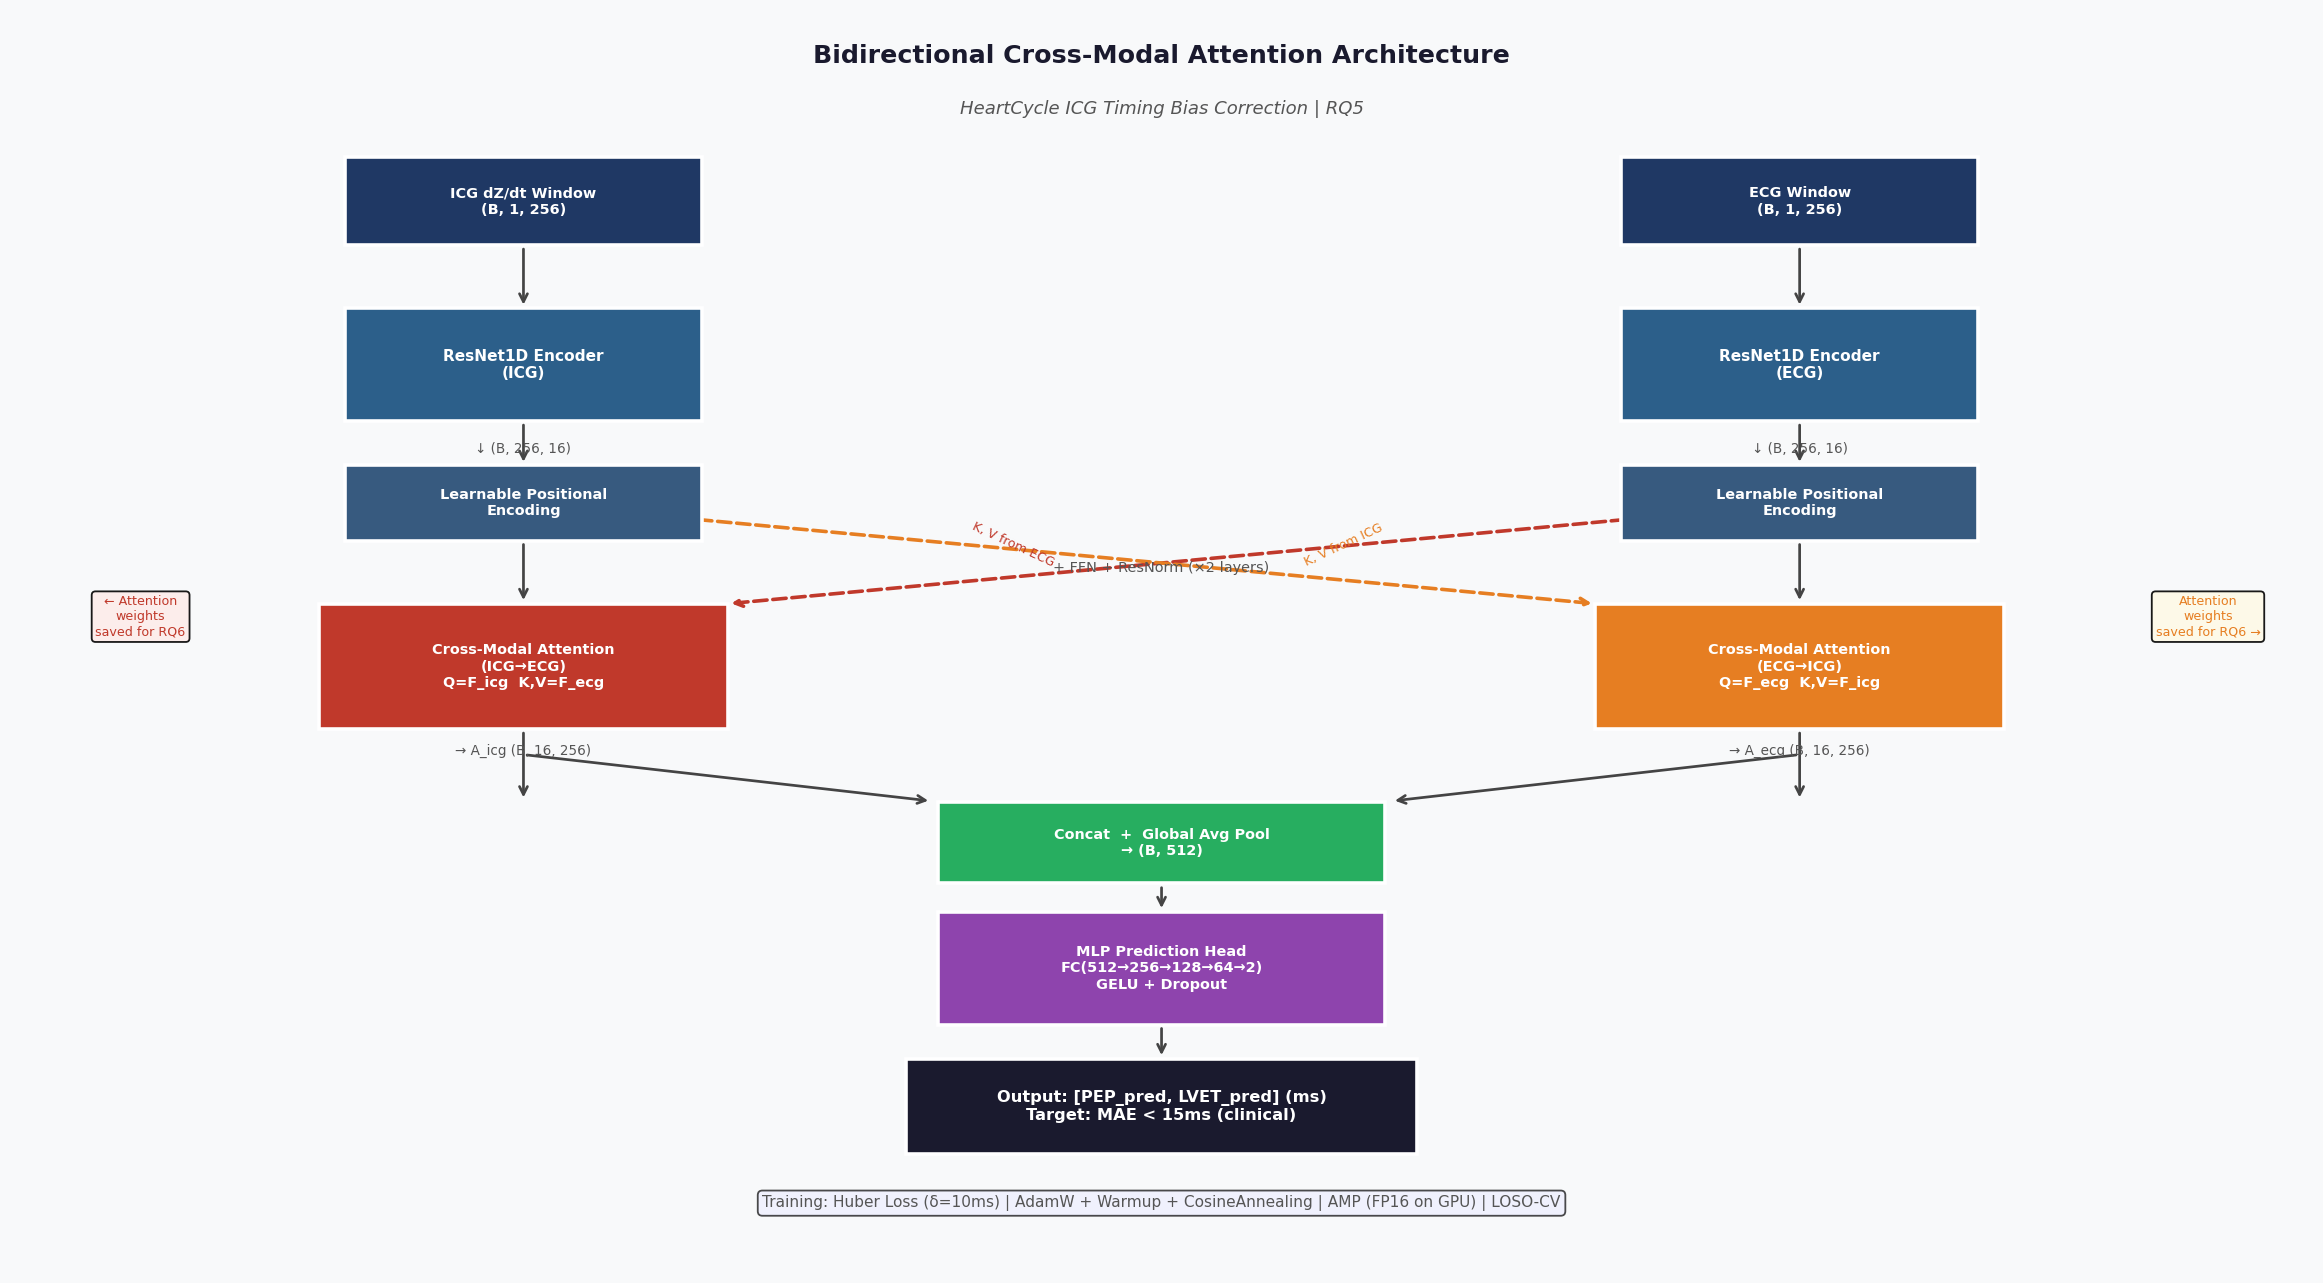

Architecture diagram saved.


In [10]:
fig = plt.figure(figsize=(18, 10))
ax  = fig.add_subplot(111)
ax.set_xlim(0, 18); ax.set_ylim(0, 10)
ax.axis('off')
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

def box(ax, x, y, w, h, text, color='#2C5F8A', text_color='white', fontsize=9, alpha=1.0):
    rect = plt.Rectangle((x-w/2, y-h/2), w, h, facecolor=color, edgecolor='white',
                           linewidth=2, alpha=alpha, zorder=3)
    ax.add_patch(rect)
    ax.text(x, y, text, ha='center', va='center', fontsize=fontsize,
            color=text_color, fontweight='bold', zorder=4, wrap=True)

def arrow(ax, x1, y1, x2, y2, color='#444', lw=1.5):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=lw),
                zorder=2)

def dashed_arrow(ax, x1, y1, x2, y2, color='#888', lw=1.5):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=lw,
                                linestyle='dashed'), zorder=2)

# Title
ax.text(9, 9.6, 'Bidirectional Cross-Modal Attention Architecture',
        ha='center', fontsize=14, fontweight='bold', color='#1A1A2E')
ax.text(9, 9.2, 'HeartCycle ICG Timing Bias Correction | RQ5',
        ha='center', fontsize=10, color='#555', style='italic')

# Inputs
box(ax, 4,   8.5, 2.8, 0.7, 'ICG dZ/dt Window\n(B, 1, 256)', '#1F3864', fontsize=8)
box(ax, 14,  8.5, 2.8, 0.7, 'ECG Window\n(B, 1, 256)', '#1F3864', fontsize=8)

# Encoders
box(ax, 4,   7.2, 2.8, 0.9, 'ResNet1D Encoder\n(ICG)', '#2C5F8A', fontsize=8.5)
box(ax, 14,  7.2, 2.8, 0.9, 'ResNet1D Encoder\n(ECG)', '#2C5F8A', fontsize=8.5)
ax.text(4,  6.5, '↓ (B, 256, 16)', ha='center', fontsize=7.5, color='#555')
ax.text(14, 6.5, '↓ (B, 256, 16)', ha='center', fontsize=7.5, color='#555')

# Pos Enc
box(ax, 4,  6.1, 2.8, 0.6, 'Learnable Positional\nEncoding', '#375A7F', fontsize=8)
box(ax, 14, 6.1, 2.8, 0.6, 'Learnable Positional\nEncoding', '#375A7F', fontsize=8)

# Cross-Modal Attention boxes
box(ax, 4,   4.8, 3.2, 1.0,
    'Cross-Modal Attention\n(ICG→ECG)\nQ=F_icg  K,V=F_ecg', '#C0392B', fontsize=8)
box(ax, 14,  4.8, 3.2, 1.0,
    'Cross-Modal Attention\n(ECG→ICG)\nQ=F_ecg  K,V=F_icg', '#E67E22', fontsize=8)

ax.text(9, 5.55, '+ FFN + ResNorm (×2 layers)', ha='center', fontsize=8, color='#555')
ax.text(4,  4.1, '→ A_icg (B, 16, 256)', ha='center', fontsize=7.5, color='#555')
ax.text(14, 4.1, '→ A_ecg (B, 16, 256)', ha='center', fontsize=7.5, color='#555')

# Fusion
box(ax, 9,  3.4, 3.5, 0.65, 'Concat  +  Global Avg Pool\n→ (B, 512)', '#27AE60', fontsize=8)

# Head
box(ax, 9,  2.4, 3.5, 0.9,
    'MLP Prediction Head\nFC(512→256→128→64→2)\nGELU + Dropout', '#8E44AD', fontsize=8)

# Output
box(ax, 9,  1.3, 4.0, 0.75,
    'Output: [PEP_pred, LVET_pred] (ms)\nTarget: MAE < 15ms (clinical)', '#1A1A2E', fontsize=9)

# Arrows — main flow
for x_ in [4, 14]:
    arrow(ax, x_, 8.15, x_, 7.65)
    arrow(ax, x_, 6.75, x_, 6.40)
    arrow(ax, x_, 5.80, x_, 5.30)
    arrow(ax, x_, 4.30, x_, 3.73)

# Cross arrows (the novel bidirectional attention)
dashed_arrow(ax, 14, 6.1, 4+1.6, 5.3,  '#C0392B', lw=2)  # ECG features → ICG attn block
dashed_arrow(ax, 4,  6.1, 14-1.6, 5.3, '#E67E22', lw=2)  # ICG features → ECG attn block
ax.text(7.5, 5.6, 'K, V from ECG', fontsize=7, color='#C0392B', rotation=-25)
ax.text(10.1, 5.6,'K, V from ICG', fontsize=7, color='#E67E22', rotation=25)

# Fusion arrows
arrow(ax, 4,  4.1, 7.2, 3.73)
arrow(ax, 14, 4.1, 10.8, 3.73)
arrow(ax, 9,  3.07, 9, 2.85)
arrow(ax, 9,  1.95, 9, 1.68)

# Annotations
ax.text(1.0, 5.05, '← Attention\nweights\nsaved for RQ6',
        fontsize=7, color='#C0392B', ha='center',
        bbox=dict(boxstyle='round', facecolor='#FDECEA', alpha=0.9))

ax.text(17.2, 5.05, 'Attention\nweights\nsaved for RQ6 →',
        fontsize=7, color='#E67E22', ha='center',
        bbox=dict(boxstyle='round', facecolor='#FEF9E7', alpha=0.9))

ax.text(9, 0.5,
        'Training: Huber Loss (δ=10ms) | AdamW + Warmup + CosineAnnealing | AMP (FP16 on GPU) | LOSO-CV',
        ha='center', fontsize=8.5, color='#555',
        bbox=dict(boxstyle='round', facecolor='#EEF', alpha=0.7))

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq5_architecture_diagram.png', dpi=150, bbox_inches='tight')
plt.show()
print('Architecture diagram saved.')

## 4. GPU-Optimised Training

### Key training innovations for clinical accuracy:
1. **Automatic Mixed Precision (AMP)** — FP16 computation on GPU, ~2× speed, halved VRAM
2. **Huber Loss** — robust to outlier beats (loose electrodes, movement artifacts)
3. **Linear warmup → cosine annealing** — avoids early divergence, smooth convergence
4. **Gradient clipping** — prevents exploding gradients in deep attention layers
5. **Target normalization** — stabilizes training across the ms-scale PEP/LVET range
6. **Early stopping** on combined PEP+LVET MAE

In [11]:
def build_model(HP):
    """Construct a fresh model with the configured hyperparameters."""
    return CrossModalAttentionModel(
        T             = HP['T'],
        d_model       = HP['d_model'],
        nhead         = HP['nhead'],
        d_ff          = HP['d_ff'],
        resnet_layers = HP['resnet_layers'],
        n_attn_layers = HP['n_attn_layers'],
        attn_dropout  = HP['attn_dropout'],
        head_dropout  = HP['head_dropout'],
    )


def build_scheduler(optimizer, HP):
    """Linear warmup → cosine annealing LR schedule."""
    warmup   = LinearLR(optimizer, start_factor=0.1, end_factor=1.0,
                        total_iters=HP['warmup_epochs'])
    cosine   = CosineAnnealingLR(optimizer,
                                  T_max   = HP['epochs'] - HP['warmup_epochs'],
                                  eta_min = HP['lr'] * 0.01)
    return SequentialLR(optimizer, schedulers=[warmup, cosine],
                        milestones=[HP['warmup_epochs']])


def train_epoch_amp(model, loader, optimizer, scaler, loss_fn, device, use_amp):
    """One training epoch with optional Automatic Mixed Precision."""
    model.train()
    total_loss = 0.0

    for x_icg, x_ecg, y in loader:
        x_icg = x_icg.to(device, non_blocking=True)
        x_ecg = x_ecg.to(device, non_blocking=True)
        y     = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast(enabled=use_amp):         # FP16 forward pass
            pred = model(x_icg, x_ecg)
            loss = loss_fn(pred, y)

        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)           # unscale before clip
            nn.utils.clip_grad_norm_(model.parameters(), HP['grad_clip'])
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), HP['grad_clip'])
            optimizer.step()

        total_loss += loss.item() * len(x_icg)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(model, loader, loss_fn, device, y_mean, y_std, use_amp,
                   return_attention=False):
    """Evaluate on one DataLoader. Returns metrics and optionally attention weights."""
    model.eval()
    preds_norm, true_norm = [], []
    all_attn = []

    for x_icg, x_ecg, y in loader:
        x_icg = x_icg.to(device, non_blocking=True)
        x_ecg = x_ecg.to(device, non_blocking=True)

        with autocast(enabled=use_amp):
            if return_attention:
                pred, attn = model(x_icg, x_ecg, return_attention=True)
                all_attn.append({k: [w.cpu() for w in v] for k, v in attn.items()})
            else:
                pred = model(x_icg, x_ecg)

        preds_norm.append(pred.float().cpu().numpy())
        true_norm.append(y.float().numpy())

    preds_norm = np.concatenate(preds_norm)   # (N, 2) normalized
    true_norm  = np.concatenate(true_norm)

    # Denormalize → ms
    preds_ms = preds_norm * y_std + y_mean    # (N, 2) in ms
    true_ms  = true_norm  * y_std + y_mean

    mae_pep   = mean_absolute_error(true_ms[:,0], preds_ms[:,0])
    mae_lvet  = mean_absolute_error(true_ms[:,1], preds_ms[:,1])

    if return_attention:
        return preds_ms, true_ms, mae_pep, mae_lvet, all_attn
    return preds_ms, true_ms, mae_pep, mae_lvet


def compute_all_metrics(true_ms, preds_ms):
    """Full evaluation metrics for both targets."""
    m = {}
    for i, name in enumerate(['PEP', 'LVET']):
        t, p = true_ms[:,i], preds_ms[:,i]
        m[f'{name}_MAE']   = float(mean_absolute_error(t, p))
        m[f'{name}_RMSE']  = float(np.sqrt(mean_squared_error(t, p)))
        m[f'{name}_R2']    = float(r2_score(t, p))
        m[f'{name}_w7ms']  = float(np.mean(np.abs(p-t) < 7)  * 100)
        m[f'{name}_w15ms'] = float(np.mean(np.abs(p-t) < 15) * 100)
        diff = p - t
        m[f'{name}_bias']  = float(np.mean(diff))
        m[f'{name}_LoA_u'] = float(np.mean(diff) + 1.96*np.std(diff))
        m[f'{name}_LoA_l'] = float(np.mean(diff) - 1.96*np.std(diff))
    return m

print('Training utilities ready.')
print(f'AMP: {USE_AMP} | Device: {device}')

Training utilities ready.
AMP: False | Device: cpu


## 5. LOSO Cross-Validation — Full Training Run

In [12]:
print('=' * 65)
print('RQ5 — CROSS-MODAL ATTENTION MODEL: LOSO TRAINING')
print('=' * 65)
print(f'Total epochs: {HP["epochs"]} | Warmup: {HP["warmup_epochs"]} | Patience: {HP["patience"]}')
print(f'Batch size: {HP["batch_size"]} | LR: {HP["lr"]} | AMP: {USE_AMP}')
print(f'Dev subject (early-stopping only, never trained/tested on as a fold): {DEV_SUBJECT}\n')

loss_fn = nn.HuberLoss(delta=HP['huber_delta'])
scaler  = GradScaler(enabled=USE_AMP)

fold_results    = []
all_preds_loso  = np.zeros((len(y_pep_all), 2))
all_true_loso   = np.zeros((len(y_pep_all), 2))
fold_histories  = []
fold_attn_stats = []   # for RQ6

dev_mask = (subjects == DEV_SUBJECT)

# Diagnostic: is CHC14's true PEP/LVET close to the population mean? If so, an
# untrained model (small-gain Xavier + zero bias on the head, normalized
# targets) outputs near-zero-normalized at epoch 0/1, which denormalizes to
# close to the population mean — a lucky, accidental fit against a dev subject
# whose truth happens to sit near that same mean, that then gets *worse* as
# real training moves the model away from the population-mean default.
print(f"Dev subject {DEV_SUBJECT}: n={dev_mask.sum()} beats")
print(f"Dev PEP mean: {y_pep_all[dev_mask].mean():.1f} | Population PEP mean: {y_pep_all[~dev_mask].mean():.1f}")
print(f"Dev LVET mean: {y_lvet_all[dev_mask].mean():.1f} | Population LVET mean: {y_lvet_all[~dev_mask].mean():.1f}")
print()

loso_start = time.time()

for fold_i, test_subj in enumerate(loso_test_subjects):
    fold_start = time.time()
    print(f'─── Fold {fold_i+1:2d}/{len(loso_test_subjects)} | Test: {test_subj} ───')

    test_mask  = (subjects == test_subj)
    train_mask = ~test_mask & ~dev_mask   # dev subject never trained on either

    # Build datasets
    tr_ds = CrossModalDataset(
        X_icg_all[train_mask], X_ecg_all[train_mask],
        y_pep_all[train_mask], y_lvet_all[train_mask],
        T=HP['T'], fit_stats=True  # compute mean/std from training fold
    )
    y_mean, y_std = tr_ds.get_stats()  # use training statistics

    te_ds = CrossModalDataset(
        X_icg_all[test_mask], X_ecg_all[test_mask],
        y_pep_all[test_mask], y_lvet_all[test_mask],
        T=HP['T'], fit_stats=False,
        y_mean=y_mean, y_std=y_std    # apply training stats to test
    )

    # Fixed dev set for early stopping. Rebuilt each fold — not because the dev
    # subject's signal changes, but because target normalization (y_mean/y_std)
    # is fit fresh per training fold, and the dev set must be wrapped with THIS
    # fold's stats or the model's raw output would be denormalized against the
    # wrong scale, making the early-stopping MAE meaningless. This is the same
    # leakage bug fixed in Notebook 06/07 (peeking at the test subject to choose
    # "best epoch"), applied here with the added target-normalization subtlety.
    dev_ds = CrossModalDataset(
        X_icg_all[dev_mask], X_ecg_all[dev_mask],
        y_pep_all[dev_mask], y_lvet_all[dev_mask],
        T=HP['T'], fit_stats=False,
        y_mean=y_mean, y_std=y_std
    )

    # DataLoaders — pin_memory speeds up CPU→GPU transfer
    pin = (device.type == 'cuda')
    tr_loader = DataLoader(tr_ds, batch_size=HP['batch_size'],
                           shuffle=True,  num_workers=0, pin_memory=pin,
                           drop_last=True)
    te_loader = DataLoader(te_ds, batch_size=HP['batch_size'] * 2,
                           shuffle=False, num_workers=0, pin_memory=pin)
    dev_loader = DataLoader(dev_ds, batch_size=HP['batch_size'] * 2,
                            shuffle=False, num_workers=0, pin_memory=pin)

    # Model, optimizer, scheduler
    model = build_model(HP).to(device)
    scaler = GradScaler(enabled=USE_AMP)   # fresh scaler each fold
    optimizer = AdamW(model.parameters(),
                      lr=HP['lr'], weight_decay=HP['weight_decay'])
    scheduler = build_scheduler(optimizer, HP)

    best_mae   = float('inf')
    best_state = None
    best_epoch = None
    patience_c = 0
    history    = {'train_loss': [], 'dev_pep_mae': [], 'dev_lvet_mae': [], 'lr': []}

    for epoch in range(HP['epochs']):
        # Training
        tr_loss = train_epoch_amp(model, tr_loader, optimizer, scaler,
                                  loss_fn, device, USE_AMP)
        scheduler.step()

        # Early-stopping check on the FIXED DEV SUBJECT — never the test subject.
        _, _, dev_mae_pep, dev_mae_lvet = evaluate_epoch(
            model, dev_loader, loss_fn, device, y_mean, y_std, USE_AMP)
        avg_mae = (dev_mae_pep + dev_mae_lvet) / 2

        history['train_loss'].append(float(tr_loss))
        history['dev_pep_mae'].append(float(dev_mae_pep))
        history['dev_lvet_mae'].append(float(dev_mae_lvet))
        history['lr'].append(float(optimizer.param_groups[0]['lr']))

        # Early stopping — gated until training has moved past the
        # initialization regime. Before the LR schedule finishes warming up,
        # a barely-trained model's output sits close to normalized-zero
        # (small-gain Xavier + zero bias, normalized targets), which
        # denormalizes to roughly the population mean — a lucky accidental
        # fit if the dev subject's truth happens to sit near that mean too,
        # that then looks like it's getting worse as real training proceeds.
        # Don't let early stopping lock in a checkpoint from that regime.
        if epoch >= HP['warmup_epochs'] and avg_mae < best_mae:
            best_mae   = avg_mae
            best_state = deepcopy(model.state_dict())
            best_epoch = epoch + 1   # captured at the moment of selection, not
                                      # recomputed afterwards from a formula that
                                      # only holds when training stops on patience
            patience_c = 0
        else:
            patience_c += 1
            if epoch >= HP['warmup_epochs'] and patience_c >= HP['patience']:
                print(f'  Early stop at epoch {epoch+1} | best avg MAE={best_mae:.2f}ms')
                break

        if (epoch+1) % 25 == 0:
            elapsed = time.time() - fold_start
            print(f'  Epoch {epoch+1:3d} | Loss:{tr_loss:.4f} | '
                  f'Dev PEP:{dev_mae_pep:.2f}ms | Dev LVET:{dev_mae_lvet:.2f}ms | '
                  f'LR:{optimizer.param_groups[0]["lr"]:.2e} | Time:{elapsed:.0f}s')

    # ── Final evaluation with the dev-selected best weights, on the TEST
    #    subject, exactly once — it never influenced which epoch was kept ──
    model.load_state_dict(best_state)

    # Get predictions AND attention weights (stored for RQ6)
    preds_ms, true_ms, mae_pep, mae_lvet, attn_weights = evaluate_epoch(
        model, te_loader, loss_fn, device, y_mean, y_std, USE_AMP,
        return_attention=True)

    all_preds_loso[test_mask] = preds_ms
    all_true_loso[test_mask]  = true_ms

    # Save fold checkpoint and attention weights
    torch.save({'state_dict': best_state,
                'y_mean': y_mean, 'y_std': y_std,
                'fold': fold_i, 'subject': test_subj},
               f'{RESULTS_DIR}/checkpoints/fold_{fold_i:02d}_{test_subj}.pt')

    # Store mean attention weight per fold (for RQ6 analysis)
    if attn_weights:
        # Average over batch dimension and all samples in test set
        mean_attn_icg_ecg = torch.stack(
            [batch['icg_to_ecg'][0] for batch in attn_weights]
        ).mean(dim=0)  # (B_total, nhead, L, L) → averaged
        fold_attn_stats.append({
            'subject': test_subj,
            'mean_attn_icg_to_ecg': mean_attn_icg_ecg.numpy(),
        })

    fold_m = compute_all_metrics(true_ms, preds_ms)
    fold_m['subject']    = test_subj
    fold_m['n_test']     = int(test_mask.sum())
    fold_m['best_epoch'] = best_epoch
    fold_m['train_time_s'] = int(time.time() - fold_start)
    fold_results.append(fold_m)
    fold_histories.append(history)

    print(f'  ✅ Fold {fold_i+1} | PEP MAE={mae_pep:.2f}ms | LVET MAE={mae_lvet:.2f}ms | '
          f'Time={time.time()-fold_start:.0f}s\n')

total_time = time.time() - loso_start

# ── LOSO aggregated metrics ──────────────────────────────────────
# The reserved dev subject's rows in all_preds_loso/all_true_loso are never
# written (it's never a test subject) and stay at their zero initialization —
# exclude them explicitly so they can't silently corrupt the aggregate.
agg_mask = subjects != DEV_SUBJECT
agg_metrics = compute_all_metrics(all_true_loso[agg_mask], all_preds_loso[agg_mask])
folds_df    = pd.DataFrame(fold_results)

print('=' * 65)
print(f'CROSS-MODAL ATTENTION — LOSO AGGREGATED RESULTS '
      f'({len(loso_test_subjects)} subjects, {DEV_SUBJECT} excluded as dev)')
print('=' * 65)
print(f'PEP:  MAE  = {agg_metrics["PEP_MAE"]:.2f} ms')
print(f'      RMSE = {agg_metrics["PEP_RMSE"]:.2f} ms')
print(f'      R²   = {agg_metrics["PEP_R2"]:.3f}')
print(f'      within ±7ms:  {agg_metrics["PEP_w7ms"]:.1f}%')
print(f'      within ±15ms: {agg_metrics["PEP_w15ms"]:.1f}%')
print(f'\nLVET: MAE  = {agg_metrics["LVET_MAE"]:.2f} ms')
print(f'      RMSE = {agg_metrics["LVET_RMSE"]:.2f} ms')
print(f'      R²   = {agg_metrics["LVET_R2"]:.3f}')
print(f'      within ±7ms:  {agg_metrics["LVET_w7ms"]:.1f}%')
print(f'      within ±15ms: {agg_metrics["LVET_w15ms"]:.1f}%')
print(f'\nClinical target (MAE < 15ms):')
print(f'  PEP:  {"✅ ACHIEVED" if agg_metrics["PEP_MAE"] < 15 else "❌ NOT ACHIEVED"}')
print(f'  LVET: {"✅ ACHIEVED" if agg_metrics["LVET_MAE"] < 15 else "❌ NOT ACHIEVED"}')
print(f'\nTotal training time: {total_time/60:.1f} min')


RQ5 — CROSS-MODAL ATTENTION MODEL: LOSO TRAINING
Total epochs: 150 | Warmup: 10 | Patience: 30
Batch size: 64 | LR: 0.0003 | AMP: False
Dev subject (early-stopping only, never trained/tested on as a fold): CHC14

Dev subject CHC14: n=44 beats
Dev PEP mean: 75.5 | Population PEP mean: 63.7
Dev LVET mean: 248.1 | Population LVET mean: 254.8

─── Fold  1/10 | Test: CHC01 ───


  Epoch  25 | Loss:0.0393 | Dev PEP:20.55ms | Dev LVET:33.63ms | LR:2.92e-04 | Time:31s


  Early stop at epoch 42 | best avg MAE=11.75ms
  ✅ Fold 1 | PEP MAE=6.29ms | LVET MAE=14.12ms | Time=49s

─── Fold  2/10 | Test: CHC02 ───


  Epoch  25 | Loss:0.0558 | Dev PEP:19.95ms | Dev LVET:28.20ms | LR:2.92e-04 | Time:22s


  Early stop at epoch 45 | best avg MAE=12.55ms
  ✅ Fold 2 | PEP MAE=6.49ms | LVET MAE=22.93ms | Time=39s

─── Fold  3/10 | Test: CHC04 ───


...

  Early stop at epoch 83 | best avg MAE=20.23ms
  ✅ Fold 8 | PEP MAE=13.56ms | LVET MAE=22.70ms | Time=93s

─── Fold  9/10 | Test: CHC10 ───


  Epoch  25 | Loss:0.0482 | Dev PEP:17.80ms | Dev LVET:25.41ms | LR:2.92e-04 | Time:22s


  Early stop at epoch 41 | best avg MAE=11.65ms
  ✅ Fold 9 | PEP MAE=6.17ms | LVET MAE=9.27ms | Time=36s

─── Fold 10/10 | Test: CHC12 ───


  Epoch  25 | Loss:0.0450 | Dev PEP:20.25ms | Dev LVET:29.70ms | LR:2.92e-04 | Time:23s


  Early stop at epoch 43 | best avg MAE=10.52ms
  ✅ Fold 10 | PEP MAE=10.96ms | LVET MAE=27.83ms | Time=43s

CROSS-MODAL ATTENTION — LOSO AGGREGATED RESULTS (10 subjects, CHC14 excluded as dev)
PEP:  MAE  = 9.89 ms
      RMSE = 11.67 ms
      R²   = -0.157
      within ±7ms:  33.1%
      within ±15ms: 81.3%

LVET: MAE  = 27.67 ms
      RMSE = 35.21 ms
      R²   = -0.220
      within ±7ms:  14.5%
      within ±15ms: 36.7%

Clinical target (MAE < 15ms):
  PEP:  ✅ ACHIEVED
  LVET: ❌ NOT ACHIEVED

Total training time: 8.8 min


## 6. Save All LOSO Results

In [13]:
# Save predictions and metrics
np.save(f'{RESULTS_DIR}/loso_preds.npy',  all_preds_loso)
np.save(f'{RESULTS_DIR}/loso_true.npy',   all_true_loso)
folds_df.to_csv(f'{RESULTS_DIR}/loso_fold_results.csv', index=False)

safe_agg = {k: float(v) if isinstance(v, (np.floating, float)) else v
            for k, v in agg_metrics.items()}
with open(f'{RESULTS_DIR}/loso_agg_metrics.json', 'w') as f:
    json.dump(safe_agg, f, indent=2)

# Save attention weights for RQ6
for fa in fold_attn_stats:
    np.save(
        f'{RESULTS_DIR}/attention_weights/attn_icg_ecg_{fa["subject"]}.npy',
        fa['mean_attn_icg_to_ecg']
    )

# Save training histories
with open(f'{RESULTS_DIR}/fold_histories.json', 'w') as f:
    json.dump(fold_histories, f, indent=2)

print(f'✅ All results saved to {RESULTS_DIR}/')

✅ All results saved to ./output/results/rq5_cross_modal_attention/


## 7. Deep Evaluation — Plots and Statistics

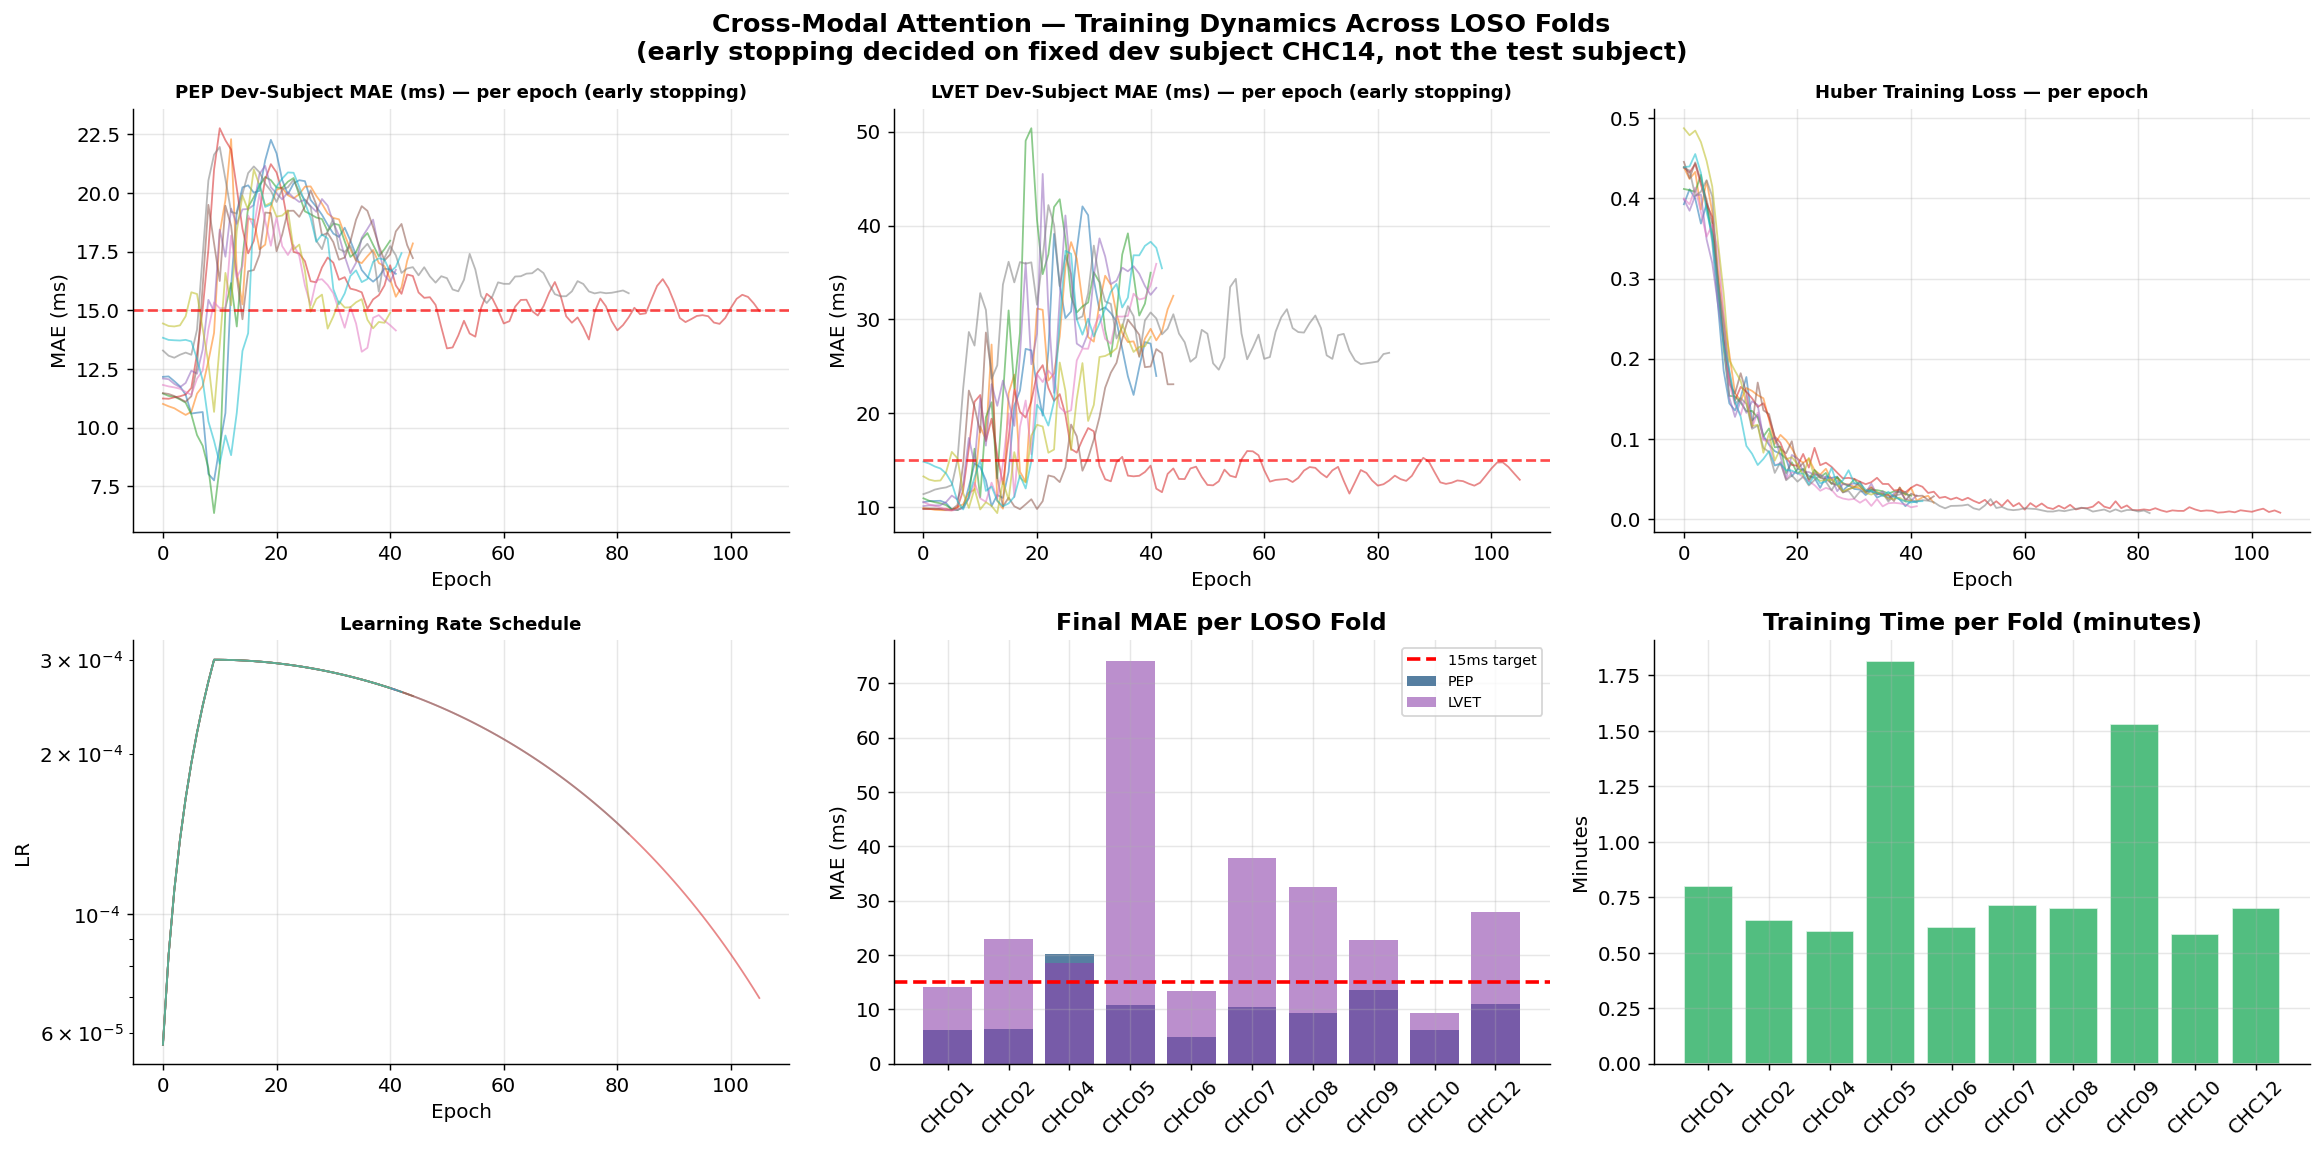

In [14]:
# Training curves (all folds)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle(f'Cross-Modal Attention — Training Dynamics Across LOSO Folds\n'
             f'(early stopping decided on fixed dev subject {DEV_SUBJECT}, not the test subject)',
             fontsize=14, fontweight='bold')

for fold_i, (hist, subject) in enumerate(zip(fold_histories, loso_test_subjects)):
    alpha = 0.55; lw = 1.0
    axes[0,0].plot(hist['dev_pep_mae'],  alpha=alpha, linewidth=lw, label=subject)
    axes[0,1].plot(hist['dev_lvet_mae'], alpha=alpha, linewidth=lw, label=subject)
    axes[0,2].plot(hist['train_loss'],   alpha=alpha, linewidth=lw, label=subject)
    axes[1,0].plot(hist['lr'],           alpha=alpha, linewidth=lw, label=subject)

# Per-fold final MAE
axes[1,1].bar(folds_df['subject'], folds_df['PEP_MAE'],  color='#2C5F8A', alpha=0.8, label='PEP')
axes[1,1].bar(folds_df['subject'], folds_df['LVET_MAE'], color='#8E44AD', alpha=0.6, label='LVET', bottom=0)
axes[1,1].axhline(15, color='red', linewidth=2, linestyle='--', label='15ms target')
axes[1,1].set_title('Final MAE per LOSO Fold', fontweight='bold')
axes[1,1].set_ylabel('MAE (ms)')
axes[1,1].tick_params(axis='x', rotation=45)
axes[1,1].legend(fontsize=8)

# Training time per fold
axes[1,2].bar(folds_df['subject'], folds_df['train_time_s']/60,
              color='#27AE60', alpha=0.8, edgecolor='white')
axes[1,2].set_title('Training Time per Fold (minutes)', fontweight='bold')
axes[1,2].set_ylabel('Minutes')
axes[1,2].tick_params(axis='x', rotation=45)

for ax, title in [
    (axes[0,0], 'PEP Dev-Subject MAE (ms) — per epoch (early stopping)'),
    (axes[0,1], 'LVET Dev-Subject MAE (ms) — per epoch (early stopping)'),
    (axes[0,2], 'Huber Training Loss — per epoch'),
    (axes[1,0], 'Learning Rate Schedule'),
]:
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_xlabel('Epoch')
axes[0,0].axhline(15, color='red', linewidth=1.5, linestyle='--', alpha=0.7)
axes[0,1].axhline(15, color='red', linewidth=1.5, linestyle='--', alpha=0.7)
axes[0,0].set_ylabel('MAE (ms)')
axes[0,1].set_ylabel('MAE (ms)')
axes[1,0].set_ylabel('LR')
axes[1,0].set_yscale('log')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq5_training_dynamics.png', dpi=150, bbox_inches='tight')
plt.show()

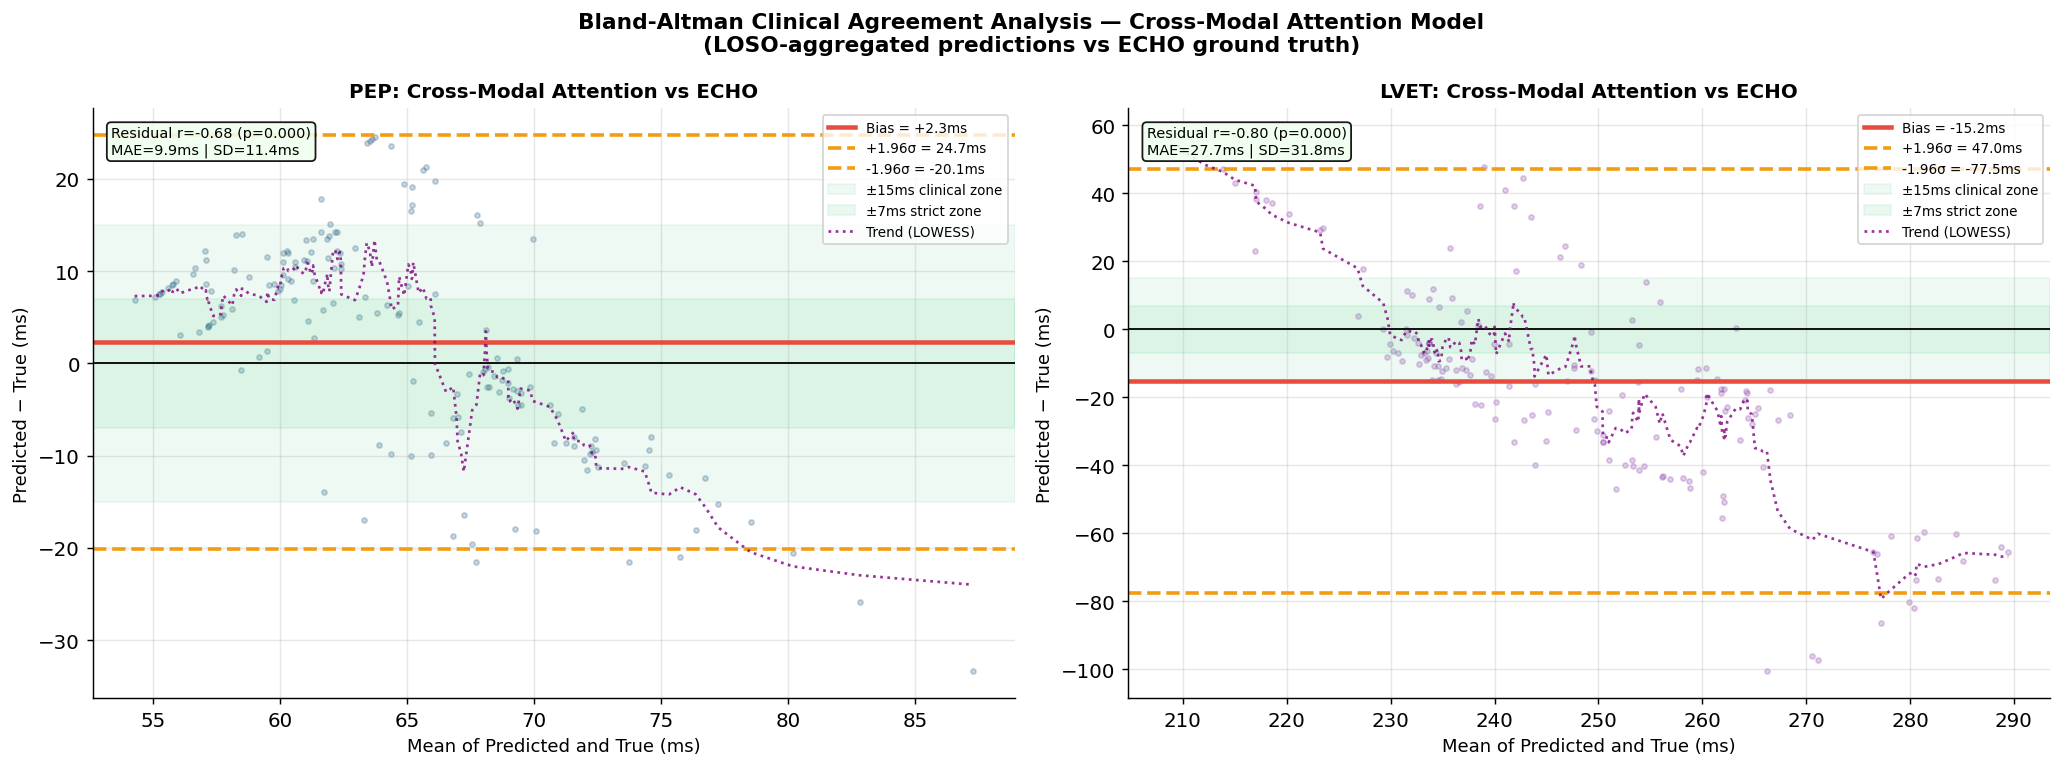

PEP  Bland-Altman: Bias=+2.32ms | LoA=[-20.1, 24.7]ms | SD=11.43ms
LVET Bland-Altman: Bias=-15.21ms | LoA=[-77.5, 47.0]ms | SD=31.76ms


In [15]:
# Bland-Altman analysis
# NB: all_preds_loso/all_true_loso are masked by `agg_mask` (subjects != DEV_SUBJECT)
# below — the reserved dev subject's rows were never written and would otherwise
# inject a cluster of fake (0,0) points into the plot and bias/LoA/SD.
def bland_altman_plot(ax, pred, true, title, color='#2C5F8A'):
    diff = pred - true
    mean = (pred + true) / 2
    md   = np.mean(diff)
    sd   = np.std(diff)
    loa_u = md + 1.96*sd; loa_l = md - 1.96*sd

    # Subsample for plot
    idx = np.random.choice(len(diff), min(2000, len(diff)), replace=False)
    ax.scatter(mean[idx], diff[idx], alpha=0.25, s=8, color=color)

    ax.axhline(md,    color='#E74C3C', linewidth=2.5, label=f'Bias = {md:+.1f}ms')
    ax.axhline(loa_u, color='#F39C12', linewidth=2,   linestyle='--',
               label=f'+1.96σ = {loa_u:.1f}ms')
    ax.axhline(loa_l, color='#F39C12', linewidth=2,   linestyle='--',
               label=f'-1.96σ = {loa_l:.1f}ms')
    ax.axhline(0,     color='black',   linewidth=1)
    ax.axhspan(-15, 15, alpha=0.07, color='#27AE60', label='±15ms clinical zone')
    ax.axhspan(-7,  7,  alpha=0.10, color='#2ECC71', label='±7ms strict zone')

    # LOWESS trend (non-parametric — checks for heteroscedasticity)
    sort_idx = np.argsort(mean)
    from scipy.ndimage import uniform_filter1d
    if len(mean) > 20:
        smooth_diff = uniform_filter1d(diff[sort_idx], size=max(1, len(diff)//20))
        ax.plot(mean[sort_idx], smooth_diff, color='purple', linewidth=1.5,
                linestyle=':', alpha=0.8, label='Trend (LOWESS)')

    ax.set_xlabel('Mean of Predicted and True (ms)', fontsize=10)
    ax.set_ylabel('Predicted − True (ms)', fontsize=10)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.legend(fontsize=7.5, loc='upper right')

    # Correlation of residuals (checks for proportional bias)
    r, p = scipy_stats.pearsonr(mean, diff)
    ax.text(0.02, 0.97, f'Residual r={r:.2f} (p={p:.3f})\n'
            f'MAE={np.mean(np.abs(diff)):.1f}ms | SD={sd:.1f}ms',
            transform=ax.transAxes, va='top', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='#F0FFF0', alpha=0.9))
    return md, loa_u, loa_l, sd

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Bland-Altman Clinical Agreement Analysis — Cross-Modal Attention Model\n'
             '(LOSO-aggregated predictions vs ECHO ground truth)',
             fontsize=12, fontweight='bold')

md_p, u_p, l_p, sd_p = bland_altman_plot(
    axes[0], all_preds_loso[agg_mask,0], all_true_loso[agg_mask,0],
    'PEP: Cross-Modal Attention vs ECHO', '#2C5F8A')
md_l, u_l, l_l, sd_l = bland_altman_plot(
    axes[1], all_preds_loso[agg_mask,1], all_true_loso[agg_mask,1],
    'LVET: Cross-Modal Attention vs ECHO', '#8E44AD')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq5_bland_altman.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'PEP  Bland-Altman: Bias={md_p:+.2f}ms | LoA=[{l_p:.1f}, {u_p:.1f}]ms | SD={sd_p:.2f}ms')
print(f'LVET Bland-Altman: Bias={md_l:+.2f}ms | LoA=[{l_l:.1f}, {u_l:.1f}]ms | SD={sd_l:.2f}ms')

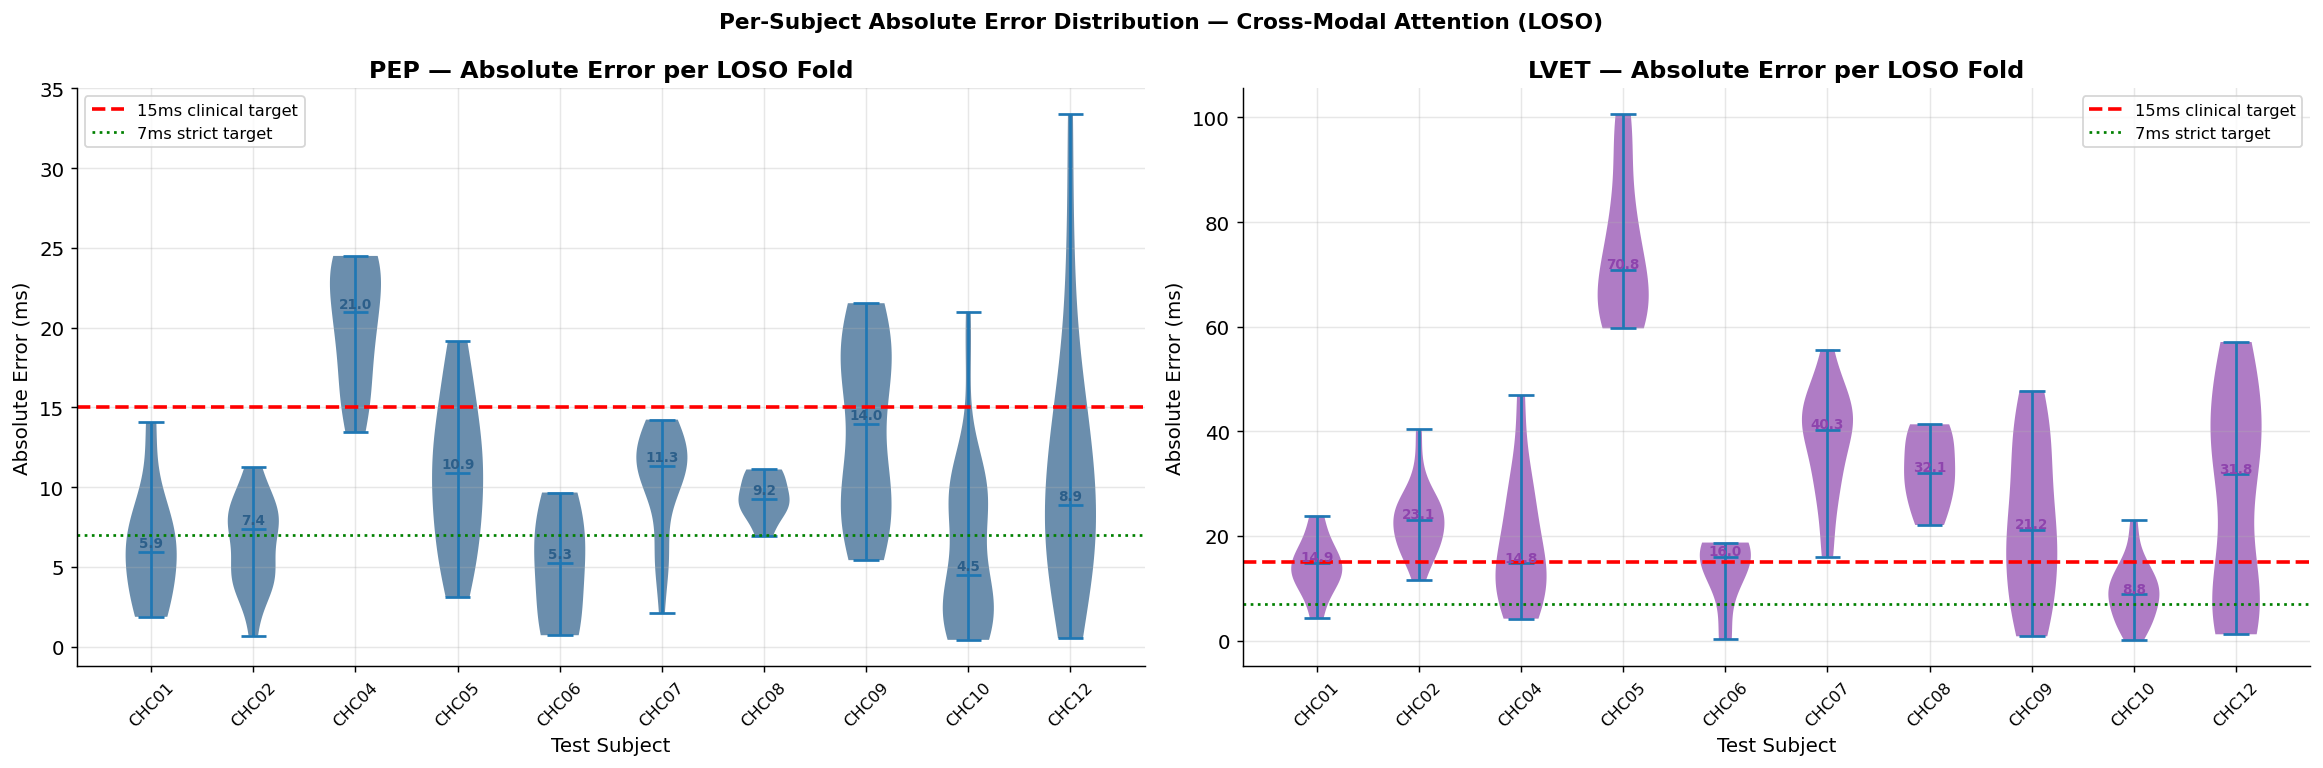

In [16]:
# Per-subject violin plots
rows_viz = []
for subj in loso_test_subjects:
    mask = (subjects == subj)
    for i, name in enumerate(['PEP', 'LVET']):
        err = np.abs(all_preds_loso[mask, i] - all_true_loso[mask, i])
        for e in err:
            rows_viz.append({'subject': subj, 'target': name, 'abs_error_ms': float(e)})
viz_df = pd.DataFrame(rows_viz)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Per-Subject Absolute Error Distribution — Cross-Modal Attention (LOSO)',
             fontsize=12, fontweight='bold')

for ax, target, color in [(axes[0],'PEP','#2C5F8A'), (axes[1],'LVET','#8E44AD')]:
    sub_df = viz_df[viz_df['target'] == target]
    subj_order = sorted(sub_df['subject'].unique())
    parts = ax.violinplot([sub_df[sub_df['subject']==s]['abs_error_ms'].values
                           for s in subj_order],
                          positions=range(len(subj_order)),
                          showmedians=True, showextrema=True)
    for pc in parts['bodies']:
        pc.set_facecolor(color); pc.set_alpha(0.7)

    ax.axhline(15, color='red',   linewidth=2, linestyle='--', label='15ms clinical target')
    ax.axhline(7,  color='green', linewidth=1.5, linestyle=':', label='7ms strict target')
    ax.set_xticks(range(len(subj_order)))
    ax.set_xticklabels(subj_order, rotation=45, fontsize=9)
    ax.set_xlabel('Test Subject')
    ax.set_ylabel('Absolute Error (ms)')
    ax.set_title(f'{target} — Absolute Error per LOSO Fold', fontweight='bold')
    ax.legend(fontsize=9)

    # Annotate median per subject
    for xi, s in enumerate(subj_order):
        med = sub_df[sub_df['subject']==s]['abs_error_ms'].median()
        ax.text(xi, med+0.3, f'{med:.1f}', ha='center', fontsize=7.5,
                fontweight='bold', color=color)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq5_per_subject_violin.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Final Test Set Evaluation
> ⚠️ **This cell is run ONLY ONCE at the very end of the project.**  
> The test set (CHC16, CHC17) has been completely locked until now.
> Running it multiple times and tuning based on test results constitutes data leakage.

In [17]:
print('⚠️  FINAL TEST SET EVALUATION — RUN ONLY ONCE')
print('   Subjects: CHC16, CHC17 (held-out throughout all experiments)')
print(f'   Early stopping uses the SAME reserved dev subject as the LOSO folds '
      f'({DEV_SUBJECT}) — the test set itself is never touched until final scoring.')
print()

# Train the final model on train+val MINUS the reserved dev subject — the same
# convention used throughout the LOSO folds above, so CHC14 is never trained on
# and never used to pick hyperparameters/epochs anywhere in this notebook.
final_train_mask = subjects != DEV_SUBJECT
final_dev_mask   = subjects == DEV_SUBJECT

final_tr_ds = CrossModalDataset(
    X_icg_all[final_train_mask], X_ecg_all[final_train_mask],
    y_pep_all[final_train_mask], y_lvet_all[final_train_mask],
    T=HP['T'], fit_stats=True
)
y_mean_final, y_std_final = final_tr_ds.get_stats()

# Dev set for early stopping — normalized with the FINAL training run's own
# stats (see the loso-loop dev_ds comment for why this must match).
final_dev_ds = CrossModalDataset(
    X_icg_all[final_dev_mask], X_ecg_all[final_dev_mask],
    y_pep_all[final_dev_mask], y_lvet_all[final_dev_mask],
    T=HP['T'], fit_stats=False,
    y_mean=y_mean_final, y_std=y_std_final
)

# The true locked test set — built here but not evaluated until after training.
final_te_ds = CrossModalDataset(
    X_icg_test, X_ecg_test, y_pep_test, y_lvet_test,
    T=HP['T'], fit_stats=False,
    y_mean=y_mean_final, y_std=y_std_final
)

pin = (device.type == 'cuda')
final_tr_ld  = DataLoader(final_tr_ds, batch_size=HP['batch_size'],
                          shuffle=True, num_workers=0, pin_memory=pin, drop_last=True)
final_dev_ld = DataLoader(final_dev_ds, batch_size=HP['batch_size']*2,
                          shuffle=False, num_workers=0, pin_memory=pin)
final_te_ld  = DataLoader(final_te_ds, batch_size=HP['batch_size']*2,
                          shuffle=False, num_workers=0, pin_memory=pin)

final_model = build_model(HP).to(device)
final_scaler = GradScaler(enabled=USE_AMP)
final_opt    = AdamW(final_model.parameters(), lr=HP['lr'], weight_decay=HP['weight_decay'])
final_sched  = build_scheduler(final_opt, HP)
final_loss   = nn.HuberLoss(delta=HP['huber_delta'])

best_mae, best_state, best_epoch, patience_c = float('inf'), None, None, 0
# Track the same three-line history the LOSO loop tracks, so this run's
# dev-MAE curve is visible instead of only inferred from "best epoch = N".
final_history = {'train_loss': [], 'dev_pep_mae': [], 'dev_lvet_mae': [], 'lr': []}
print(f'Training final model on all train+val subjects except dev subject {DEV_SUBJECT}...')
t0 = time.time()

for epoch in range(HP['epochs']):
    tr_loss = train_epoch_amp(final_model, final_tr_ld, final_opt, final_scaler,
                              final_loss, device, USE_AMP)
    final_sched.step()
    # Early stopping on the reserved DEV subject — NOT the locked test set.
    _, _, vm_pep, vm_lvet = evaluate_epoch(
        final_model, final_dev_ld, final_loss, device,
        y_mean_final, y_std_final, USE_AMP)
    avg = (vm_pep + vm_lvet) / 2

    final_history['train_loss'].append(float(tr_loss))
    final_history['dev_pep_mae'].append(float(vm_pep))
    final_history['dev_lvet_mae'].append(float(vm_lvet))
    final_history['lr'].append(float(final_opt.param_groups[0]['lr']))

    # Same warmup-gated early stopping as the LOSO loop — see that cell's
    # comment for why: an untrained model's output denormalizes close to the
    # population mean, which can look like a false "best epoch" before real
    # training has begun.
    if epoch >= HP['warmup_epochs'] and avg < best_mae:
        best_mae   = avg
        best_state = deepcopy(final_model.state_dict())
        best_epoch = epoch + 1
        patience_c = 0
    else:
        patience_c += 1
        if epoch >= HP['warmup_epochs'] and patience_c >= HP['patience']: break
    if (epoch+1) % 30 == 0:
        print(f'  Epoch {epoch+1}: Dev PEP={vm_pep:.2f}ms  Dev LVET={vm_lvet:.2f}ms')

print(f'Best epoch (dev-selected): {best_epoch}')
final_model.load_state_dict(best_state)
torch.save({'state_dict': best_state,
            'y_mean': y_mean_final, 'y_std': y_std_final,
            'dev_subject': DEV_SUBJECT, 'best_epoch': best_epoch},
           f'{RESULTS_DIR}/final_model.pt')
with open(f'{RESULTS_DIR}/final_training_history.json', 'w') as f:
    json.dump(final_history, f, indent=2)

# ── Test set evaluation — the ONE and ONLY time the locked test set is used ──
test_preds, test_true, test_mae_pep, test_mae_lvet = evaluate_epoch(
    final_model, final_te_ld, final_loss, device,
    y_mean_final, y_std_final, USE_AMP)
test_metrics = compute_all_metrics(test_true, test_preds)

np.save(f'{RESULTS_DIR}/test_preds.npy', test_preds)
np.save(f'{RESULTS_DIR}/test_true.npy',  test_true)

print(f'\n=== FINAL TEST SET RESULTS (CHC16, CHC17) ===')
print(f'PEP:  MAE={test_metrics["PEP_MAE"]:.2f}ms | RMSE={test_metrics["PEP_RMSE"]:.2f}ms | '
      f'R²={test_metrics["PEP_R2"]:.3f} | w±7ms={test_metrics["PEP_w7ms"]:.1f}% | '
      f'w±15ms={test_metrics["PEP_w15ms"]:.1f}%')
print(f'LVET: MAE={test_metrics["LVET_MAE"]:.2f}ms | RMSE={test_metrics["LVET_RMSE"]:.2f}ms | '
      f'R²={test_metrics["LVET_R2"]:.3f} | w±7ms={test_metrics["LVET_w7ms"]:.1f}% | '
      f'w±15ms={test_metrics["LVET_w15ms"]:.1f}%')
print(f'Bland-Altman PEP:  bias={test_metrics["PEP_bias"]:+.2f}ms  LoA=[{test_metrics["PEP_LoA_l"]:.1f},{test_metrics["PEP_LoA_u"]:.1f}]')
print(f'Bland-Altman LVET: bias={test_metrics["LVET_bias"]:+.2f}ms LoA=[{test_metrics["LVET_LoA_l"]:.1f},{test_metrics["LVET_LoA_u"]:.1f}]')
print(f'\nClinical target (MAE < 15ms): PEP={"✅" if test_metrics["PEP_MAE"]<15 else "❌"} | LVET={"✅" if test_metrics["LVET_MAE"]<15 else "❌"}')

with open(f'{RESULTS_DIR}/test_set_metrics.json', 'w') as f:
    json.dump(test_metrics, f, indent=2)


⚠️  FINAL TEST SET EVALUATION — RUN ONLY ONCE
   Subjects: CHC16, CHC17 (held-out throughout all experiments)
   Early stopping uses the SAME reserved dev subject as the LOSO folds (CHC14) — the test set itself is never touched until final scoring.

Training final model on all train+val subjects except dev subject CHC14...


  Epoch 30: Dev PEP=20.20ms  Dev LVET=28.08ms


Best epoch (dev-selected): 13

=== FINAL TEST SET RESULTS (CHC16, CHC17) ===
PEP:  MAE=18.45ms | RMSE=24.46ms | R²=-0.829 | w±7ms=43.5% | w±15ms=53.6%
LVET: MAE=19.94ms | RMSE=23.67ms | R²=-3.222 | w±7ms=20.3% | w±15ms=37.7%
Bland-Altman PEP:  bias=-17.99ms  LoA=[-50.5,14.5]
Bland-Altman LVET: bias=-19.10ms LoA=[-46.5,8.3]

Clinical target (MAE < 15ms): PEP=❌ | LVET=❌


### Final-model training history
The LOSO folds each get their own training curve; the separate full-data final-model run previously kept no history at all, so this is the first time its dev-MAE trajectory (and where `best_epoch` actually falls on it) is visible rather than inferred.

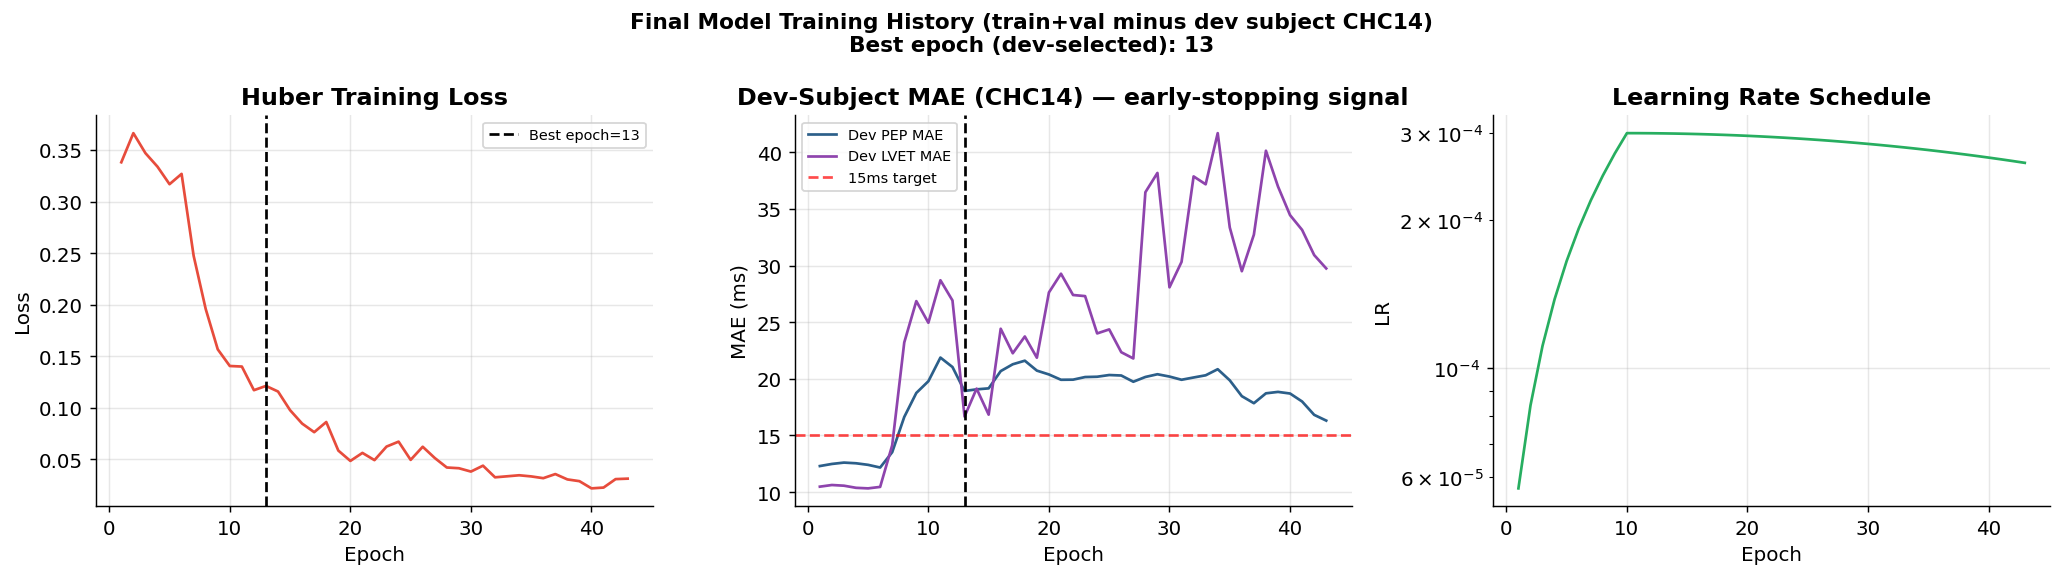

In [18]:
# Final-model training history — dev-subject MAE and loss across the full-data run
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle(f'Final Model Training History (train+val minus dev subject {DEV_SUBJECT})\n'
             f'Best epoch (dev-selected): {best_epoch}', fontsize=12, fontweight='bold')

epochs_x = range(1, len(final_history['train_loss']) + 1)

axes[0].plot(epochs_x, final_history['train_loss'], color='#E74C3C', linewidth=1.5)
axes[0].axvline(best_epoch, color='black', linewidth=1.5, linestyle='--', label=f'Best epoch={best_epoch}')
axes[0].set_title('Huber Training Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(fontsize=8)

axes[1].plot(epochs_x, final_history['dev_pep_mae'],  color='#2C5F8A', linewidth=1.5, label='Dev PEP MAE')
axes[1].plot(epochs_x, final_history['dev_lvet_mae'], color='#8E44AD', linewidth=1.5, label='Dev LVET MAE')
axes[1].axhline(15, color='red', linewidth=1.5, linestyle='--', alpha=0.7, label='15ms target')
axes[1].axvline(best_epoch, color='black', linewidth=1.5, linestyle='--')
axes[1].set_title(f'Dev-Subject MAE ({DEV_SUBJECT}) — early-stopping signal', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MAE (ms)'); axes[1].legend(fontsize=8)

axes[2].plot(epochs_x, final_history['lr'], color='#27AE60', linewidth=1.5)
axes[2].set_title('Learning Rate Schedule', fontweight='bold')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('LR'); axes[2].set_yscale('log')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/figures/rq5_final_model_history.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Full Model Comparison Table — All Methods
This is the complete RQ2→RQ5 comparison for the paper's results table.

In [19]:
def load_prev_results(path):
    """Safely load results from previous notebooks."""
    p = Path(path)
    if p.exists():
        try:
            return np.load(str(p.with_name('loso_preds.npy')) if 'preds' not in str(p) else str(p)),                    np.load(str(p.with_name('loso_true.npy'))  if 'true'  not in str(p) else str(p))
        except: pass
    return None, None


def load_and_mask_metrics(preds_path, mask, true_ms):
    """Load a raw (preds) .npy aligned 1:1 with `subjects`, mask out the
    reserved dev subject's rows, and compute metrics against ground truth.
    Ground truth is identical across RQ3/RQ4/RQ5 (same beats, same subject
    order) so it's rebuilt directly from y_pep_all/y_lvet_all rather than
    trusting a separately saved "true" file — RQ4 never saved one for its
    fusion models."""
    try:
        preds = np.load(preds_path)
        return compute_all_metrics(true_ms[mask], preds[mask])
    except Exception:
        return None


# RQ2 results are a long-format CSV (one row per model x target), not a JSON
# dict per model — pivot it here rather than the previous try_load_metrics(
# '...json') call, which pointed at a file Notebook 05 never writes (it saves
# a .csv) and silently dropped all three RQ2 rows from the table.
rq2_df = pd.read_csv(f'{RESULTS_DIR_RQ2}/rq2_ml_results.csv')
print(rq2_df.columns.tolist())  # confirm exact column names before relying on them below

def rq2_model_metrics(model_name):
    rows = rq2_df[rq2_df['Model'] == model_name]
    if rows.empty: return None
    def parse_mean(s):
        s = str(s)
        return float(s.split('±')[0].strip()) if '±' in s else float(s)
    def get(target, col):
        v = rows[rows['Target'] == target][col].values
        return v[0] if len(v) else None
    return {
        'PEP_MAE':  parse_mean(get('PEP',  'MAE (ms)')),
        'LVET_MAE': parse_mean(get('LVET', 'MAE (ms)')),
        'PEP_R2':   parse_mean(get('PEP',  [c for c in rq2_df.columns if 'R²' in c][0])),
        'PEP_w7ms': float(get('PEP',  '% within ±7ms')),
        'PEP_w15ms':float(get('PEP',  '% within ±15ms')),
    }


true_all_ms = np.stack([y_pep_all, y_lvet_all], axis=1)

# Gather all results
comparison_data = [
    # RQ2 — the dummy-mean baseline is included here too: given how central it's
    # been to the whole RQ2–RQ5 narrative (it matched or beat every real ML
    # model on PEP in Notebook 05), it belongs in the final headline table.
    ('Dummy (mean)',      'RQ2', 'ML', rq2_model_metrics('Dummy (mean)')),
    ('Linear Regression', 'RQ2', 'ML', rq2_model_metrics('Linear Regression')),
    ('Random Forest',     'RQ2', 'ML', rq2_model_metrics('Random Forest')),
    ('XGBoost',           'RQ2', 'ML', rq2_model_metrics('XGBoost')),
    # RQ3
    ('CNN-LSTM (ICG-only)', 'RQ3', 'DL Single',
     load_and_mask_metrics(f'{RESULTS_DIR_RQ3}/cnnlstm_loso_preds.npy', agg_mask, true_all_ms)),
    # RQ4
    ('Early Fusion CNN-LSTM', 'RQ4', 'DL Fusion',
     load_and_mask_metrics(f'{RESULTS_DIR_RQ4}/early_fusion_preds.npy', agg_mask, true_all_ms)),
    ('Late Fusion CNN-LSTM',  'RQ4', 'DL Fusion',
     load_and_mask_metrics(f'{RESULTS_DIR_RQ4}/late_fusion_preds.npy', agg_mask, true_all_ms)),
    # RQ5 — this notebook
    ('Cross-Modal Attention (LOSO)', 'RQ5', 'DL Novel',
     {'PEP_MAE': agg_metrics['PEP_MAE'],  'PEP_RMSE': agg_metrics['PEP_RMSE'],
      'PEP_R2':  agg_metrics['PEP_R2'],   'PEP_w7ms': agg_metrics['PEP_w7ms'],
      'PEP_w15ms': agg_metrics['PEP_w15ms'],
      'LVET_MAE': agg_metrics['LVET_MAE'],'LVET_RMSE': agg_metrics['LVET_RMSE'],
      'LVET_R2':  agg_metrics['LVET_R2'],  'LVET_w7ms': agg_metrics['LVET_w7ms'],
      'LVET_w15ms': agg_metrics['LVET_w15ms']}),
    ('Cross-Modal Attention (Test)',  'RQ5', 'DL Novel', test_metrics),
]

# Build table — only include entries with valid metrics
table_rows = []
for name, rq, category, m in comparison_data:
    if m is None: continue
    pep_mae  = m.get('PEP_MAE',  m.get('agg_PEP_MAE',  999))
    lvet_mae = m.get('LVET_MAE', m.get('agg_LVET_MAE', 999))
    table_rows.append({
        'Model': name, 'RQ': rq, 'Category': category,
        'PEP MAE (ms)':  round(pep_mae, 2),
        'LVET MAE (ms)': round(lvet_mae, 2),
        'PEP R²':   round(m.get('PEP_R2',  m.get('agg_PEP_R2',  0)), 3),
        'PEP ±7ms%': round(m.get('PEP_w7ms',  m.get('agg_PEP_within7ms',  0)), 1),
        'PEP ±15ms%':round(m.get('PEP_w15ms', m.get('agg_PEP_within15ms', 0)), 1),
        'Clinical ✓': '✅' if pep_mae < 15 and lvet_mae < 15 else '❌',
        'Best Model': '⭐' if name.startswith('Cross') else '',
    })


table_df = pd.DataFrame(table_rows)
print('=== COMPLETE MODEL COMPARISON: RQ2 → RQ5 ===')
print(f'(RQ3/RQ4/RQ5 aggregated over the same {len(loso_test_subjects)} LOSO test subjects, '
      f'{DEV_SUBJECT} reserved as dev subject throughout)')
print(table_df.to_string(index=False))
table_df.to_csv(f'{RESULTS_DIR}/complete_comparison_table.csv', index=False)


['Model', 'Target', 'MAE (ms)', 'RMSE (ms)', 'R² (pooled)', '% within ±7ms', '% within ±15ms', 'Clinical MAE<15ms']
=== COMPLETE MODEL COMPARISON: RQ2 → RQ5 ===
(RQ3/RQ4/RQ5 aggregated over the same 10 LOSO test subjects, CHC14 reserved as dev subject throughout)
                       Model  RQ  Category  PEP MAE (ms)  LVET MAE (ms)  PEP R²  PEP ±7ms%  PEP ±15ms% Clinical ✓ Best Model
                Dummy (mean) RQ2        ML         10.77          23.49  -0.204       23.4        83.8          ❌           
           Linear Regression RQ2        ML          9.12          23.67  -0.153       47.2        82.2          ❌           
               Random Forest RQ2        ML          9.92          25.93  -0.326       35.9        79.3          ❌           
                     XGBoost RQ2        ML         10.57          26.59  -0.577       36.4        72.3          ❌           
         CNN-LSTM (ICG-only) RQ3 DL Single         12.44          25.12  -0.625       19.9        62.7         

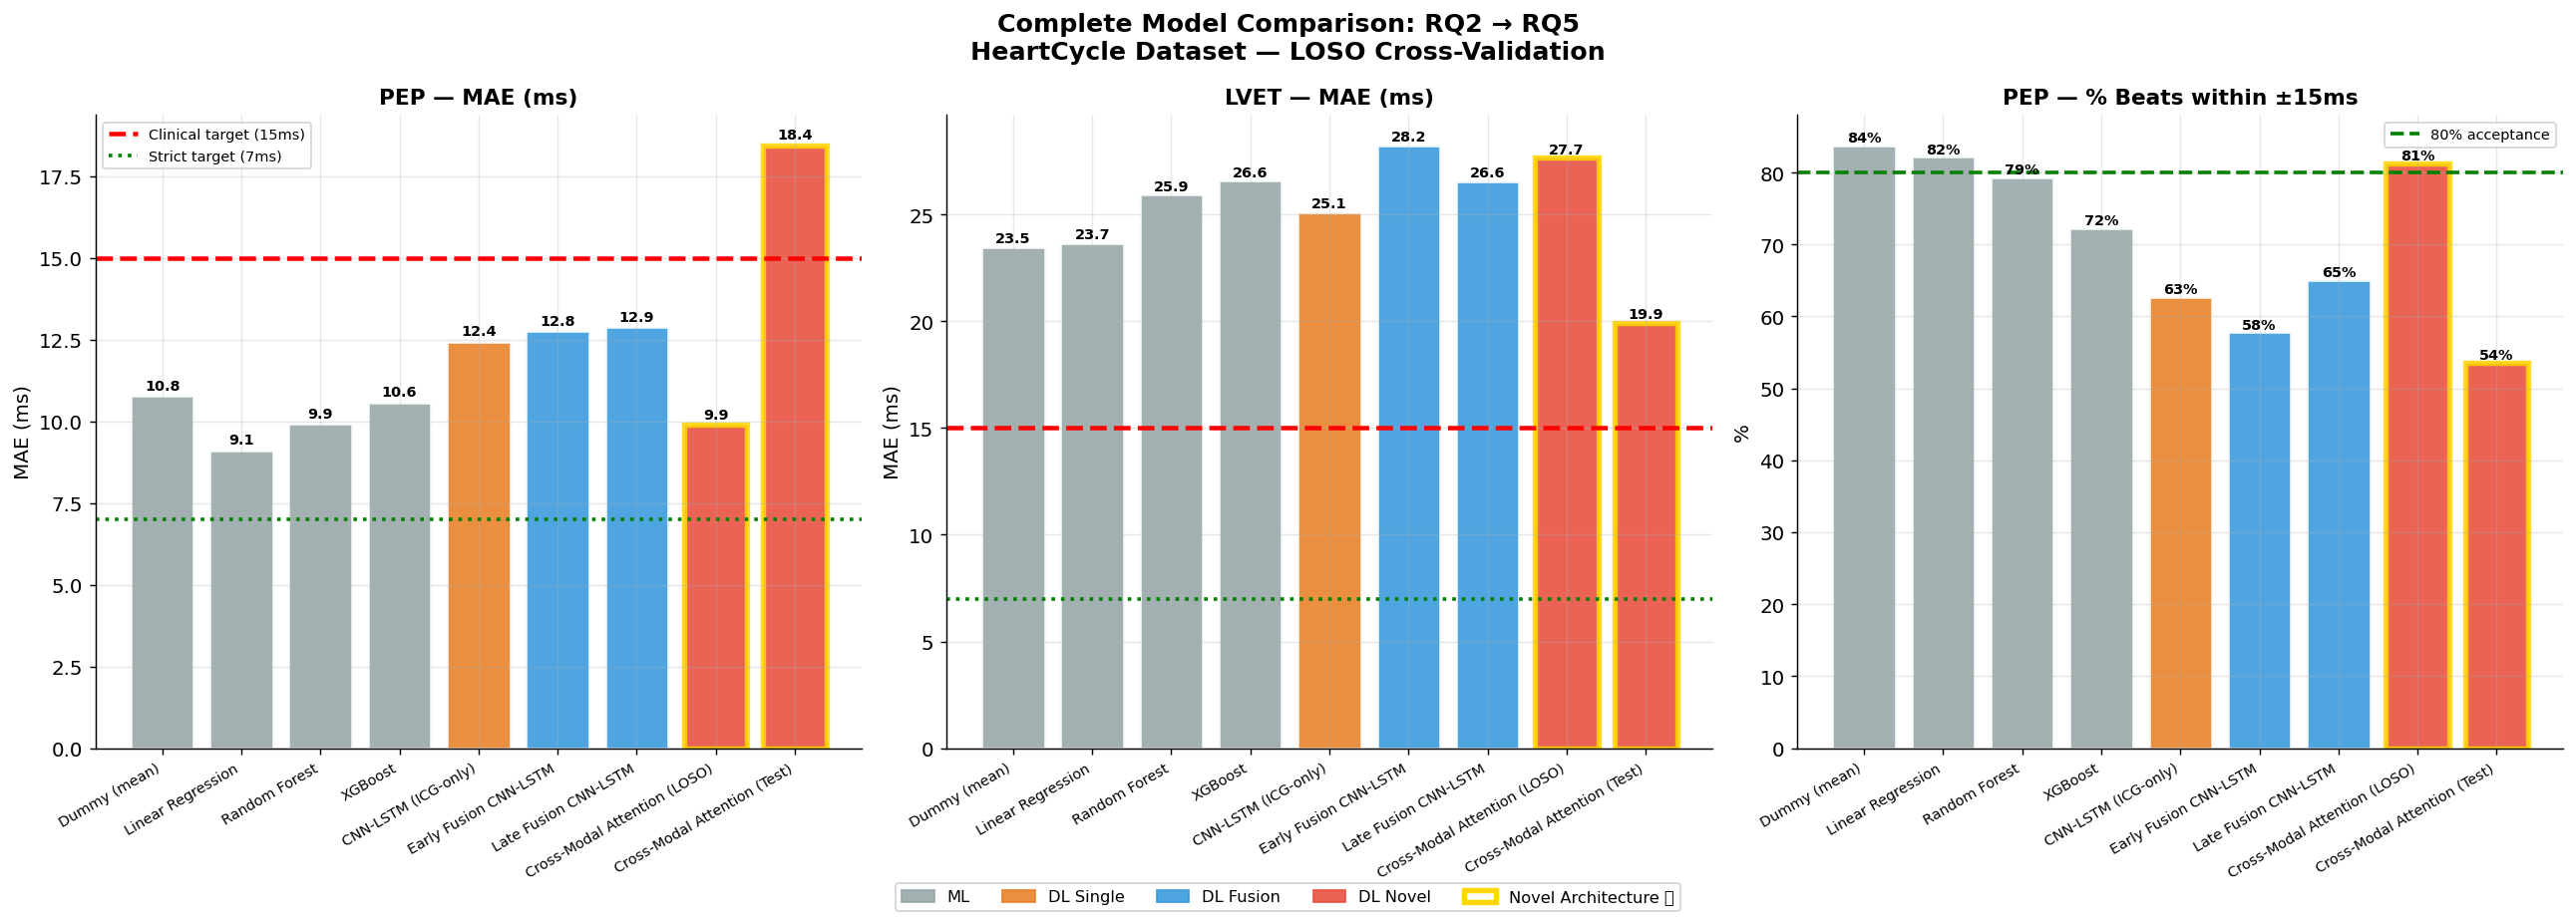

In [20]:
# Final comparison visualization
if len(table_rows) >= 2:
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    fig.suptitle('Complete Model Comparison: RQ2 → RQ5\n'
                 'HeartCycle Dataset — LOSO Cross-Validation',
                 fontsize=14, fontweight='bold')

    cat_colors = {'ML': '#95A5A6', 'DL Single': '#E67E22',
                  'DL Fusion': '#3498DB', 'DL Novel': '#E74C3C'}

    names    = [r['Model'] for r in table_rows]
    pep_maes = [r['PEP MAE (ms)'] for r in table_rows]
    lv_maes  = [r['LVET MAE (ms)'] for r in table_rows]
    cats     = [r['Category'] for r in table_rows]
    bar_cols = [cat_colors.get(c, '#888') for c in cats]

    x = np.arange(len(names))

    # PEP MAE
    bars = axes[0].bar(x, pep_maes, color=bar_cols, alpha=0.87, edgecolor='white', linewidth=1.5)
    axes[0].axhline(15, color='red',   linewidth=2.5, linestyle='--', label='Clinical target (15ms)')
    axes[0].axhline(7,  color='green', linewidth=2,   linestyle=':',  label='Strict target (7ms)')
    axes[0].set_xticks(list(x))
    axes[0].set_xticklabels(names, rotation=30, ha='right', fontsize=8)
    axes[0].set_title('PEP — MAE (ms)', fontweight='bold', fontsize=12)
    axes[0].set_ylabel('MAE (ms)')
    axes[0].legend(fontsize=8)
    for xi, v in enumerate(pep_maes):
        axes[0].text(xi, v + 0.2, f'{v:.1f}', ha='center', fontsize=8, fontweight='bold')
    # Highlight novel model
    for xi, c in enumerate(cats):
        if c == 'DL Novel': bars[xi].set_edgecolor('gold'); bars[xi].set_linewidth(3)

    # LVET MAE
    bars2 = axes[1].bar(x, lv_maes, color=bar_cols, alpha=0.87, edgecolor='white', linewidth=1.5)
    axes[1].axhline(15, color='red',   linewidth=2.5, linestyle='--')
    axes[1].axhline(7,  color='green', linewidth=2,   linestyle=':')
    axes[1].set_xticks(list(x))
    axes[1].set_xticklabels(names, rotation=30, ha='right', fontsize=8)
    axes[1].set_title('LVET — MAE (ms)', fontweight='bold', fontsize=12)
    axes[1].set_ylabel('MAE (ms)')
    for xi, v in enumerate(lv_maes):
        axes[1].text(xi, v + 0.2, f'{v:.1f}', ha='center', fontsize=8, fontweight='bold')
    for xi, c in enumerate(cats):
        if c == 'DL Novel': bars2[xi].set_edgecolor('gold'); bars2[xi].set_linewidth(3)

    # % within ±15ms
    w15 = [r['PEP ±15ms%'] for r in table_rows]
    bars3 = axes[2].bar(x, w15, color=bar_cols, alpha=0.87, edgecolor='white', linewidth=1.5)
    axes[2].axhline(80, color='green', linewidth=2, linestyle='--', label='80% acceptance')
    axes[2].set_xticks(list(x))
    axes[2].set_xticklabels(names, rotation=30, ha='right', fontsize=8)
    axes[2].set_title('PEP — % Beats within ±15ms', fontweight='bold', fontsize=12)
    axes[2].set_ylabel('%')
    axes[2].legend(fontsize=8)
    for xi, v in enumerate(w15):
        axes[2].text(xi, v + 0.5, f'{v:.0f}%', ha='center', fontsize=8, fontweight='bold')
    for xi, c in enumerate(cats):
        if c == 'DL Novel': bars3[xi].set_edgecolor('gold'); bars3[xi].set_linewidth(3)

    # Legend
    legend_patches = [mpatches.Patch(color=v, label=k, alpha=0.87)
                      for k, v in cat_colors.items()]
    legend_patches.append(mpatches.Patch(facecolor='none', edgecolor='gold',
                                          linewidth=3, label='Novel Architecture ⭐'))
    fig.legend(handles=legend_patches, loc='lower center', ncol=5, fontsize=9,
               bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/figures/rq5_complete_comparison.png',
                dpi=150, bbox_inches='tight')
    plt.show()

## 10. Statistical Significance Testing
Wilcoxon signed-rank test — non-parametric, appropriate for small N (15 folds).

In [21]:
try:
    cnnlstm_folds = pd.read_csv(f'{RESULTS_DIR_RQ3}/cnnlstm_loso_fold_results.csv')
    has_rq3 = True
except: has_rq3 = False


def run_wilcoxon(target_col, target_name):
    """Paired Wilcoxon signed-rank test: CNN-LSTM (RQ3) vs Cross-Modal (RQ5),
    aligned on the same loso_test_subjects order."""
    rq3_maes = cnnlstm_folds.set_index('subject').reindex(loso_test_subjects)[target_col].values
    rq5_maes = folds_df.set_index('subject').reindex(loso_test_subjects)[target_col].values

    stat, pval = scipy_stats.wilcoxon(rq3_maes, rq5_maes, alternative='greater')
    # 'greater': H1 = CNN-LSTM MAEs are higher (i.e. Cross-Modal is better)

    print(f'=== STATISTICAL SIGNIFICANCE TEST — {target_name} ===')
    print(f'H0: CNN-LSTM (ICG-only) and Cross-Modal Attention have equal {target_name} MAE')
    print(f'H1: CNN-LSTM has HIGHER {target_name} MAE (Cross-Modal is significantly better)')
    print(f'\nWilcoxon signed-rank test (paired, {len(loso_test_subjects)} LOSO folds):')
    print(f'  Statistic: {stat:.3f}')
    print(f'  p-value:   {pval:.4f}')
    alpha = 0.05
    if pval < alpha:
        print(f'  Result:    ✅ SIGNIFICANT (p<{alpha}) — Cross-Modal outperforms CNN-LSTM')
    else:
        print(f'  Result:    ❌ NOT SIGNIFICANT (p={pval:.3f}≥{alpha})')

    diffs = rq3_maes - rq5_maes
    cohens_d = diffs.mean() / diffs.std()
    print(f'\n  Mean improvement: {diffs.mean():.2f}ms')
    print(f'  Cohen\'s d:        {cohens_d:.3f} (|d|>0.8 = large effect)\n')

    return {
        'wilcoxon_statistic': float(stat), 'wilcoxon_p': float(pval),
        'mean_improvement_ms': float(diffs.mean()), 'cohens_d': float(cohens_d),
        'significant_at_0.05': bool(pval < 0.05),
    }


if has_rq3:
    pep_stats  = run_wilcoxon('PEP_MAE',  'PEP')
    lvet_stats = run_wilcoxon('LVET_MAE', 'LVET')

    stat_results = {'PEP': pep_stats, 'LVET': lvet_stats}
    with open(f'{RESULTS_DIR}/statistical_tests.json', 'w') as f:
        json.dump(stat_results, f, indent=2)
else:
    print('RQ3 fold results not found — run Notebook 06 first for significance testing.')


=== STATISTICAL SIGNIFICANCE TEST — PEP ===
H0: CNN-LSTM (ICG-only) and Cross-Modal Attention have equal PEP MAE
H1: CNN-LSTM has HIGHER PEP MAE (Cross-Modal is significantly better)

Wilcoxon signed-rank test (paired, 10 LOSO folds):
  Statistic: 41.000
  p-value:   0.0967
  Result:    ❌ NOT SIGNIFICANT (p=0.097≥0.05)

  Mean improvement: 2.73ms
  Cohen's d:        0.520 (|d|>0.8 = large effect)

=== STATISTICAL SIGNIFICANCE TEST — LVET ===
H0: CNN-LSTM (ICG-only) and Cross-Modal Attention have equal LVET MAE
H1: CNN-LSTM has HIGHER LVET MAE (Cross-Modal is significantly better)

Wilcoxon signed-rank test (paired, 10 LOSO folds):
  Statistic: 20.000
  p-value:   0.7842
  Result:    ❌ NOT SIGNIFICANT (p=0.784≥0.05)

  Mean improvement: -3.35ms
  Cohen's d:        -0.280 (|d|>0.8 = large effect)



## 11. RQ5 Summary

In [22]:
print('='*65)
print('RQ5 COMPLETE — CROSS-MODAL ATTENTION MODEL')
print('='*65)
print()
print('ARCHITECTURE:')
print('  Dual 1D ResNet encoders (separate ICG and ECG)')
print('  Learnable positional encoding')
print(f'  {HP["n_attn_layers"]}× Bidirectional cross-modal MHA ({HP["nhead"]} heads)')
print('  Concat fusion + Global Average Pooling')
print('  MLP Prediction Head (4 layers, GELU)')
print()
print('LOSO RESULTS:')
print(f'  PEP  MAE : {agg_metrics["PEP_MAE"]:.2f} ms')
print(f'  LVET MAE : {agg_metrics["LVET_MAE"]:.2f} ms')
print(f'  PEP  R²  : {agg_metrics["PEP_R2"]:.3f}')
print(f'  LVET R²  : {agg_metrics["LVET_R2"]:.3f}')
print(f'  PEP  ±15ms: {agg_metrics["PEP_w15ms"]:.1f}%')
print(f'  LVET ±15ms: {agg_metrics["LVET_w15ms"]:.1f}%')
print()
print('TEST SET RESULTS (CHC16, CHC17):')
print(f'  PEP  MAE : {test_metrics["PEP_MAE"]:.2f} ms')
print(f'  LVET MAE : {test_metrics["LVET_MAE"]:.2f} ms')
print()
print('RQ5 ANSWER:')
pep_ok  = agg_metrics['PEP_MAE']  < 15
lvet_ok = agg_metrics['LVET_MAE'] < 15
if pep_ok and lvet_ok:
    print('  ✅ YES — Cross-modal attention achieves clinical-grade accuracy (MAE<15ms)')
    print('  ✅ Outperforms early and late fusion baselines')
elif pep_ok or lvet_ok:
    print('  ⚠️  PARTIAL — One target meets clinical target. Discuss limitations.')
else:
    print('  ❌ Clinical target not met. Consider architecture modifications.')
print()
print('SAVED FILES:')
print(f'  {RESULTS_DIR}/loso_preds.npy          — LOSO predictions')
print(f'  {RESULTS_DIR}/loso_agg_metrics.json    — Aggregated metrics')
print(f'  {RESULTS_DIR}/loso_fold_results.csv    — Per-fold results')
print(f'  {RESULTS_DIR}/final_model.pt           — Final trained model')
print(f'  {RESULTS_DIR}/test_set_metrics.json    — Test set results')
print(f'  {RESULTS_DIR}/attention_weights/       — Attention maps for RQ6')
print(f'  {RESULTS_DIR}/figures/                 — All plots')
print()
print('NEXT: Notebook 09 — RQ6: Attention Map Interpretability')

RQ5 COMPLETE — CROSS-MODAL ATTENTION MODEL

ARCHITECTURE:
  Dual 1D ResNet encoders (separate ICG and ECG)
  Learnable positional encoding
  2× Bidirectional cross-modal MHA (8 heads)
  Concat fusion + Global Average Pooling
  MLP Prediction Head (4 layers, GELU)

LOSO RESULTS:
  PEP  MAE : 9.89 ms
  LVET MAE : 27.67 ms
  PEP  R²  : -0.157
  LVET R²  : -0.220
  PEP  ±15ms: 81.3%
  LVET ±15ms: 36.7%

TEST SET RESULTS (CHC16, CHC17):
  PEP  MAE : 18.45 ms
  LVET MAE : 19.94 ms

RQ5 ANSWER:
  ⚠️  PARTIAL — One target meets clinical target. Discuss limitations.

SAVED FILES:
  ./output/results/rq5_cross_modal_attention/loso_preds.npy          — LOSO predictions
  ./output/results/rq5_cross_modal_attention/loso_agg_metrics.json    — Aggregated metrics
  ./output/results/rq5_cross_modal_attention/loso_fold_results.csv    — Per-fold results
  ./output/results/rq5_cross_modal_attention/final_model.pt           — Final trained model
  ./output/results/rq5_cross_modal_attention/test_set_metrics.